In [2]:
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, transforms
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import os

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [3]:
# Simple cnn to differentiate between fruits
# 4 convolutional layers and 3 linear layers
# https://data.mendeley.com/datasets/rg254yr63x/1

class fruitClassificationCNN(nn.Module):
    def __init__(self, num_classes=6): 
        super(fruitClassificationCNN, self).__init__()
        
        self.features = nn.Sequential(
            #Block 1
            nn.Conv2d(3, 32, kernel_size=5, padding=2),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            #Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            #Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
        )
        
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),    
            nn.Linear(1024, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),       
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x
        

In [4]:
# Data preprocessing: added lots of augmentations to make model better at generalization
# Has 6 classes with 3 fruits and whether they are fresh or rotten
# Made one dataset on only fresh peaches and fresh pomegranates so easier to train

datadir = "/Users/sasv/Documents/Stanford/REU/archive/"
num_training_images = 229
num_validation_images = 20
num_test_images = 1

class CustomDataset(Dataset):
    def __init__(self, root_dir, rnge, num_class=6, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.images = []
        self.labels = []
        
        # Get class names from folder names
        self.classes = sorted(os.listdir(root_dir))[1:]
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.classes)}
        #print(self.class_to_idx)
        
        # Collect all image paths and labels
        class_count = 0
        for class_name in self.classes:
            if class_name.startswith('.'):  # skips .DS_Store and any hidden file
                continue
            print(class_name)
            class_count += 1
            class_path = os.path.join(root_dir, class_name)
            for img_file in os.listdir(class_path)[rnge[0]:rnge[1]]:
                if img_file.endswith(('.jpg')):
                    self.images.append(os.path.join(class_path, img_file))
                    self.labels.append(self.class_to_idx[class_name])
            if class_count == num_class:
                break
        
        print('\n')
    
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):
        img_path = self.images[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]
        
        if self.transform:
            image = self.transform(image)
        
        return image, label
    
train_transforms = transforms.Compose([
    transforms.Resize((32, 32)),
    
    # Add more augmentation
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.2,
    ),
    transforms.RandomGrayscale(p=0.1),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1)  # random shift
    ),
    
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])
    
train_dataset = CustomDataset(root_dir=datadir, rnge=(0, num_training_images), transform=train_transforms)
short_dataset = CustomDataset(root_dir=datadir, rnge=(0, num_training_images//6), transform=train_transforms)
twoclasstrain_dataset = CustomDataset(root_dir=datadir, rnge=(0, num_training_images), num_class=2, transform=train_transforms)
print(len(twoclasstrain_dataset))
validation_dataset = CustomDataset(root_dir=datadir, rnge=(num_training_images, num_training_images + num_validation_images), transform=val_transforms)
twoclassval_dataset = CustomDataset(root_dir=datadir, rnge=(num_training_images, num_training_images + num_validation_images), num_class=2, transform=train_transforms)
test_dataset = CustomDataset(root_dir=datadir, rnge=(num_training_images + num_validation_images, num_training_images + num_validation_images + num_test_images), transform=val_transforms)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4, multiprocessing_context='fork')
short_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4, multiprocessing_context='fork')
twoclasstrain_loader = DataLoader(twoclasstrain_dataset, batch_size=32, shuffle=True, num_workers=4, multiprocessing_context='fork')
val_loader = DataLoader(validation_dataset, batch_size=32, shuffle=True, num_workers=4, multiprocessing_context='fork')
twoclassval_loader = DataLoader(twoclassval_dataset, batch_size=32, shuffle=True, num_workers=4, multiprocessing_context='fork')

fresh_peaches_done
fresh_pomegranates_done
fresh_strawberries_done
rotten_peaches_done
rotten_pomegranates_done
rotten_strawberries_done


fresh_peaches_done
fresh_pomegranates_done
fresh_strawberries_done
rotten_peaches_done
rotten_pomegranates_done
rotten_strawberries_done


fresh_peaches_done
fresh_pomegranates_done


458
fresh_peaches_done
fresh_pomegranates_done
fresh_strawberries_done
rotten_peaches_done
rotten_pomegranates_done
rotten_strawberries_done


fresh_peaches_done
fresh_pomegranates_done


fresh_peaches_done
fresh_pomegranates_done
fresh_strawberries_done
rotten_peaches_done
rotten_pomegranates_done
rotten_strawberries_done




In [5]:
# Train simple cnn
# Plateaus at training accuracy of 90% and validation accuracy of 85%

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

model = fruitClassificationCNN(num_classes=6).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
num_epochs = 300

# Track losses
train_losses = []
val_losses   = []
train_accs   = []
val_accs     = []

best_val_loss = float('inf')

for epoch in range(num_epochs):
    model.train()
    running_train_loss = 0.0
    correct_train      = 0
    total_train        = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        # Track loss and accuracy
        running_train_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total_train  += labels.size(0)
        correct_train += (predicted == labels).sum().item()
    
    avg_train_loss = running_train_loss / len(train_loader)
    train_acc      = 100 * correct_train / total_train
        
    model.eval()  # set model to evaluation mode
    running_val_loss = 0.0
    correct_val      = 0
    total_val        = 0
    
    with torch.no_grad():  # no gradients needed for validation
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            
            outputs  = model(images)
            loss     = criterion(outputs, labels)
            
            # Track loss and accuracy
            running_val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total_val    += labels.size(0)
            correct_val  += (predicted == labels).sum().item()
    
    avg_val_loss = running_val_loss / len(val_loader)
    val_acc      = 100 * correct_val / total_val
    
    # Save losses
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)
    
    # Print progress
    print(f"Epoch [{epoch+1}/{num_epochs}]  "
          f"Train Loss: {avg_train_loss:.4f}  Train Acc: {train_acc:.2f}%  "
          f"Val Loss: {avg_val_loss:.4f}  Val Acc: {val_acc:.2f}%")
    
    # Save model if validation loss improved
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), 'best_model.pth')
        print(f"  -> Model saved with val loss: {best_val_loss:.4f}")


Using device: mps
Epoch [1/300]  Train Loss: 1.8281  Train Acc: 21.91%  Val Loss: 1.6567  Val Acc: 34.17%
  -> Model saved with val loss: 1.6567
Epoch [2/300]  Train Loss: 1.6863  Train Acc: 28.17%  Val Loss: 1.6198  Val Acc: 35.83%
  -> Model saved with val loss: 1.6198
Epoch [3/300]  Train Loss: 1.6505  Train Acc: 30.35%  Val Loss: 1.5929  Val Acc: 43.33%
  -> Model saved with val loss: 1.5929
Epoch [4/300]  Train Loss: 1.6134  Train Acc: 32.02%  Val Loss: 1.6005  Val Acc: 37.50%
Epoch [5/300]  Train Loss: 1.6017  Train Acc: 33.11%  Val Loss: 1.4726  Val Acc: 35.83%
  -> Model saved with val loss: 1.4726
Epoch [6/300]  Train Loss: 1.5829  Train Acc: 35.37%  Val Loss: 1.4744  Val Acc: 36.67%
Epoch [7/300]  Train Loss: 1.5684  Train Acc: 35.01%  Val Loss: 1.4829  Val Acc: 40.00%
Epoch [8/300]  Train Loss: 1.5369  Train Acc: 36.90%  Val Loss: 1.4628  Val Acc: 45.83%
  -> Model saved with val loss: 1.4628
Epoch [9/300]  Train Loss: 1.5276  Train Acc: 37.48%  Val Loss: 1.4222  Val Acc: 43

Epoch [84/300]  Train Loss: 0.7939  Train Acc: 71.18%  Val Loss: 0.8509  Val Acc: 67.50%
Epoch [85/300]  Train Loss: 0.7713  Train Acc: 71.91%  Val Loss: 0.8208  Val Acc: 70.00%
Epoch [86/300]  Train Loss: 0.7455  Train Acc: 71.83%  Val Loss: 0.7057  Val Acc: 70.83%
Epoch [87/300]  Train Loss: 0.7839  Train Acc: 71.83%  Val Loss: 0.7859  Val Acc: 65.83%
Epoch [88/300]  Train Loss: 0.7607  Train Acc: 73.29%  Val Loss: 0.7846  Val Acc: 72.50%
Epoch [89/300]  Train Loss: 0.7155  Train Acc: 73.80%  Val Loss: 0.8937  Val Acc: 65.83%
Epoch [90/300]  Train Loss: 0.7062  Train Acc: 73.80%  Val Loss: 0.6945  Val Acc: 72.50%
  -> Model saved with val loss: 0.6945
Epoch [91/300]  Train Loss: 0.7453  Train Acc: 72.20%  Val Loss: 0.8507  Val Acc: 69.17%
Epoch [92/300]  Train Loss: 0.7362  Train Acc: 70.82%  Val Loss: 0.7490  Val Acc: 72.50%
Epoch [93/300]  Train Loss: 0.7253  Train Acc: 73.44%  Val Loss: 0.7626  Val Acc: 77.50%
Epoch [94/300]  Train Loss: 0.7086  Train Acc: 74.31%  Val Loss: 0.6803

Epoch [173/300]  Train Loss: 0.4211  Train Acc: 84.50%  Val Loss: 0.8863  Val Acc: 77.50%
Epoch [174/300]  Train Loss: 0.4539  Train Acc: 84.13%  Val Loss: 0.6864  Val Acc: 74.17%
Epoch [175/300]  Train Loss: 0.4406  Train Acc: 84.35%  Val Loss: 0.6023  Val Acc: 78.33%
Epoch [176/300]  Train Loss: 0.4405  Train Acc: 84.28%  Val Loss: 0.8337  Val Acc: 71.67%
Epoch [177/300]  Train Loss: 0.4545  Train Acc: 83.26%  Val Loss: 0.5996  Val Acc: 80.00%
Epoch [178/300]  Train Loss: 0.4440  Train Acc: 83.70%  Val Loss: 1.1069  Val Acc: 68.33%
Epoch [179/300]  Train Loss: 0.4692  Train Acc: 83.19%  Val Loss: 0.7641  Val Acc: 79.17%
Epoch [180/300]  Train Loss: 0.4459  Train Acc: 84.28%  Val Loss: 0.9011  Val Acc: 75.83%
Epoch [181/300]  Train Loss: 0.4110  Train Acc: 84.57%  Val Loss: 0.7169  Val Acc: 80.83%
Epoch [182/300]  Train Loss: 0.4869  Train Acc: 81.95%  Val Loss: 0.6443  Val Acc: 78.33%
Epoch [183/300]  Train Loss: 0.3714  Train Acc: 86.32%  Val Loss: 0.8306  Val Acc: 79.17%
Epoch [184

Epoch [264/300]  Train Loss: 0.3704  Train Acc: 87.34%  Val Loss: 0.6481  Val Acc: 82.50%
Epoch [265/300]  Train Loss: 0.3518  Train Acc: 87.41%  Val Loss: 0.7920  Val Acc: 79.17%
Epoch [266/300]  Train Loss: 0.2965  Train Acc: 90.32%  Val Loss: 0.7900  Val Acc: 81.67%
Epoch [267/300]  Train Loss: 0.3617  Train Acc: 88.06%  Val Loss: 0.8711  Val Acc: 80.00%
Epoch [268/300]  Train Loss: 0.3301  Train Acc: 88.65%  Val Loss: 0.7342  Val Acc: 78.33%
Epoch [269/300]  Train Loss: 0.3419  Train Acc: 87.77%  Val Loss: 0.7788  Val Acc: 75.83%
Epoch [270/300]  Train Loss: 0.2977  Train Acc: 89.67%  Val Loss: 0.7683  Val Acc: 80.00%
Epoch [271/300]  Train Loss: 0.3459  Train Acc: 88.43%  Val Loss: 0.9414  Val Acc: 74.17%
Epoch [272/300]  Train Loss: 0.3229  Train Acc: 88.43%  Val Loss: 0.7371  Val Acc: 82.50%
Epoch [273/300]  Train Loss: 0.3101  Train Acc: 88.21%  Val Loss: 0.7559  Val Acc: 81.67%
Epoch [274/300]  Train Loss: 0.2910  Train Acc: 90.10%  Val Loss: 0.7778  Val Acc: 80.00%
Epoch [275

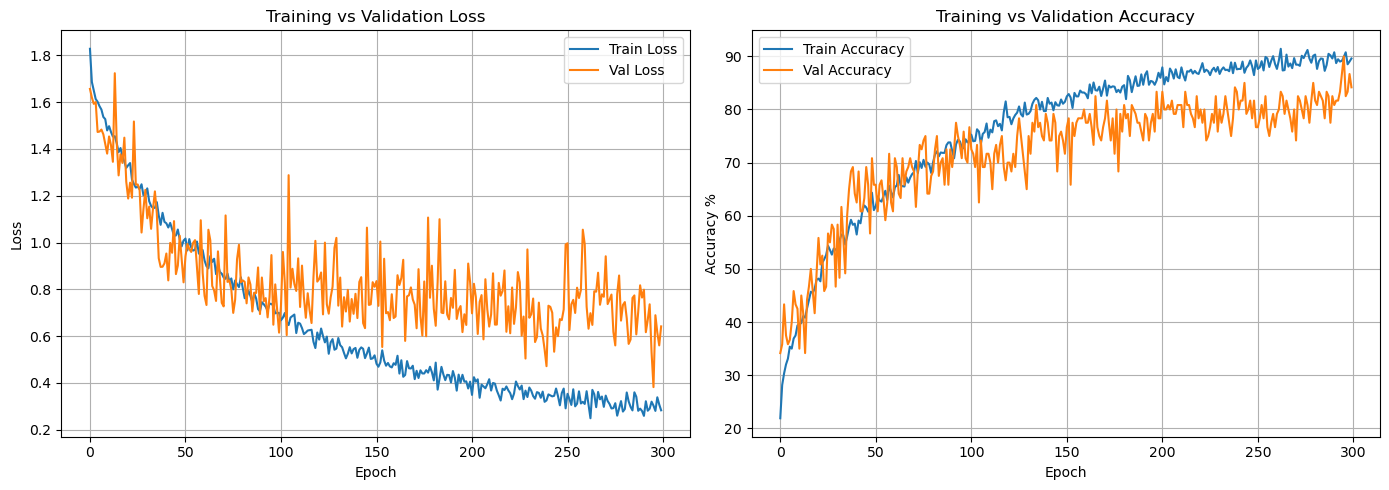

In [6]:
import matplotlib.pyplot as plt

def plot_losses(train_losses, val_losses, train_accs, val_accs):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Loss plot
    ax1.plot(train_losses, label='Train Loss')
    ax1.plot(val_losses,   label='Val Loss')
    ax1.set_title('Training vs Validation Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)
    
    # Accuracy plot
    ax2.plot(train_accs, label='Train Accuracy')
    ax2.plot(val_accs,   label='Val Accuracy')
    ax2.set_title('Training vs Validation Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy %')
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()

plot_losses(train_losses, val_losses, train_accs, val_accs)

['fresh_peaches_done', 'fresh_pomegranates_done', 'fresh_strawberries_done', 'rotten_peaches_done', 'rotten_pomegranates_done', 'rotten_strawberries_done']


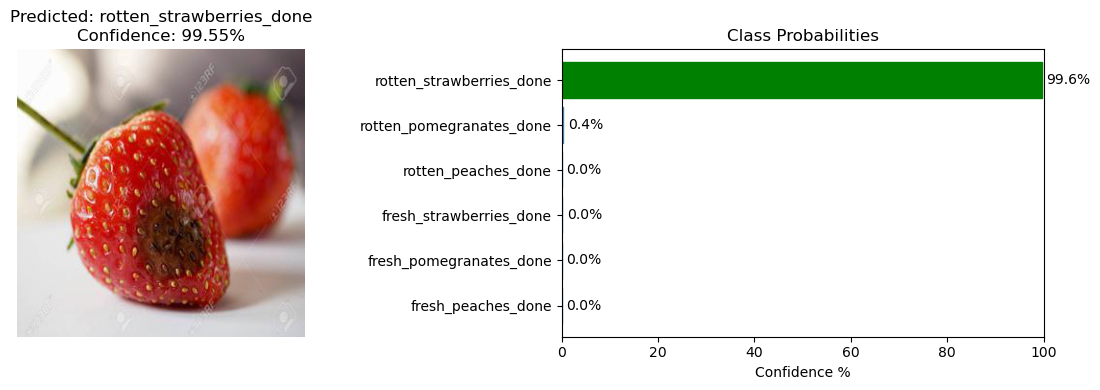

Predicted Class:  rotten_strawberries_done
Confidence:       99.55%

All Probabilities:
  fresh_peaches_done: 0.00%
  fresh_pomegranates_done: 0.01%
  fresh_strawberries_done: 0.05%
  rotten_peaches_done: 0.01%
  rotten_pomegranates_done: 0.38%
  rotten_strawberries_done: 99.55%


In [71]:
def predict_image(image_path, model, class_names, device):
    
    # Transform the image (same as val transforms, NO augmentation)
    transform = transforms.Compose([
        transforms.Resize((32, 32)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])
    
    # Load and transform image
    image     = Image.open(image_path).convert('RGB')
    input     = transform(image).unsqueeze(0)  # add batch dimension [1, 3, 32, 32]
    input     = input.to(device)
    
    # Make prediction
    model.eval()
    with torch.no_grad():
        outputs     = model(input)
        
        # Get probabilities
        probs       = torch.softmax(outputs, dim=1)
        
        # Get top prediction
        confidence, predicted = torch.max(probs, 1)
        
        predicted_class = class_names[predicted.item()]
        confidence      = confidence.item() * 100
    
    return predicted_class, confidence, probs


def show_prediction(image_path, model, class_names, device):
    
    predicted_class, confidence, probs = predict_image(
        image_path, model, class_names, device
    )
    
    # Plot image and predictions
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    
    # Show image
    image = Image.open(image_path)
    ax1.imshow(image)
    ax1.set_title(f"Predicted: {predicted_class}\nConfidence: {confidence:.2f}%")
    ax1.axis('off')
    
    # Show probability bar chart
    probs_list = probs.squeeze().cpu().numpy()
    bars       = ax2.barh(class_names, probs_list * 100)
    ax2.set_xlabel('Confidence %')
    ax2.set_title('Class Probabilities')
    ax2.set_xlim(0, 100)
    
    # Highlight the predicted bar in green
    for i, bar in enumerate(bars):
        if class_names[i] == predicted_class:
            bar.set_color('green')
        else:
            bar.set_color('steelblue')
    
    # Add percentage labels on bars
    for bar, prob in zip(bars, probs_list):
        ax2.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
                 f'{prob*100:.1f}%', va='center')
    
    plt.tight_layout()
    plt.show()
    
    print(f"Predicted Class:  {predicted_class}")
    print(f"Confidence:       {confidence:.2f}%")
    print("\nAll Probabilities:")
    for class_name, prob in zip(class_names, probs_list):
        print(f"  {class_name:15s}: {prob*100:.2f}%")
        
class_names = train_dataset.classes
print(class_names)  # ['apple', 'banana', 'grape', ...]

# Predict a single image
show_prediction(
    image_path = '/Users/sasv/Documents/Stanford/REU/archive/rotten_strawberries_done/rotten_strawberry_298.jpg',
    model      = model,
    class_names= class_names,
    device     = device
)


In [8]:
# Extract Features from Saved CNN

# Load saved CNN
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

model = fruitClassificationCNN(num_classes=6).to(device)
model.load_state_dict(torch.load('/Users/sasv/documents/stanford/ReU/best_cnn_model.pth', map_location=device))
model.eval()

# Create a feature extractor (everything up to classifier)
class CNNFeatureExtractor(nn.Module):
    def __init__(self, trained_model):
        super(CNNFeatureExtractor, self).__init__()
        
        # Keep only the feature extraction part
        self.features      = trained_model.features
        self.flatten       = nn.Flatten()
    
    def forward(self, x):
        x = self.features(x)
        x = self.flatten(x)
        return x

# Create extractor and freeze all weights
feature_extractor = CNNFeatureExtractor(model).to(device)
for param in feature_extractor.parameters():
    param.requires_grad = False   # freeze CNN weights
    
feature_extractor.eval()
print("Feature extractor created and frozen")

# Check output dimension
test_input   = torch.randn(1, 3, 32, 32).to(device)
test_output  = feature_extractor(test_input)
feature_dim  = test_output.shape[1]
print(f"Feature dimension: {feature_dim}")  # should be 256*4*4 = 4096

# Function for extraction
def extract_all_features(extractor, dataloader, device):
    """Extract CNN features for entire dataset"""
    all_features = []
    all_labels   = []
    
    with torch.no_grad():
        for images, labels in dataloader:
            images   = images.to(device)
            features = extractor(images)
            
            # Move to CPU and convert to numpy
            all_features.append(features.cpu().numpy())
            all_labels.append(labels.numpy())
    
    features = np.concatenate(all_features, axis=0)  # (N, feature_dim)
    labels   = np.concatenate(all_labels,   axis=0)  # (N,)
    
    return features, labels

print("Extracting training features...")
train_features, train_labels = extract_all_features(feature_extractor, train_loader, device)

print("Extracting validation features...")
val_features, val_labels     = extract_all_features(feature_extractor, val_loader, device)

# Global normalization
def global_normalize(train_f, val_f):
    mean        = train_f.mean(axis=0)
    std         = train_f.std(axis=0) + 1e-8
    train_norm  = (train_f - mean) / std
    val_norm    = (val_f   - mean) / std
    return train_norm, val_norm

#train_features, val_features = global_normalize(train_features, val_features)

print(f"Train features shape: {train_features.shape}")
print(f"Val features shape:   {val_features.shape}")

'''
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Reduce features to a smaller but more meaningful representation
# PCA finds the most important directions in feature space

scaler = StandardScaler()
train_features_scaled = scaler.fit_transform(train_features)
val_features_scaled   = scaler.transform(val_features)

# Keep top 128 principal components
pca = PCA(n_components=528)
train_features_pca = pca.fit_transform(train_features_scaled)
val_features_pca   = pca.transform(val_features_scaled)
pca_feature_dim    = train_features_pca.shape[1]

print(f"Variance explained: {pca.explained_variance_ratio_.sum():.2%}")
print(f"New feature dim:    {pca_feature_dim}")
'''

Feature extractor created and frozen
Feature dimension: 4096
Extracting training features...
Extracting validation features...
Train features shape: (1374, 4096)
Val features shape:   (120, 4096)


'\nfrom sklearn.decomposition import PCA\nfrom sklearn.preprocessing import StandardScaler\n\n# Reduce features to a smaller but more meaningful representation\n# PCA finds the most important directions in feature space\n\nscaler = StandardScaler()\ntrain_features_scaled = scaler.fit_transform(train_features)\nval_features_scaled   = scaler.transform(val_features)\n\n# Keep top 128 principal components\npca = PCA(n_components=528)\ntrain_features_pca = pca.fit_transform(train_features_scaled)\nval_features_pca   = pca.transform(val_features_scaled)\npca_feature_dim    = train_features_pca.shape[1]\n\nprint(f"Variance explained: {pca.explained_variance_ratio_.sum():.2%}")\nprint(f"New feature dim:    {pca_feature_dim}")\n'

In [117]:
# Make LUT linear layers at the end of CNN
# Attempted both completely LUT linear layers and having first linear layer be normal matmul
# Trained for 6 classes, with 1 matmul layer and 2 LUT linear layers, the model reached
#     val accuracy of 85% which is very close to 3 matmul layers
# Trained for 6 classes, wtih 3 LUT linear layers of n_tab 64 and n_comp 8, the model
#     reached val acc of 65% but overtrained as train_acc reached 99%
# Main problem with 3 LUT linear layers is dimension too high and that is difficult for 
#     LUT to use all information
# Attempted to use PCA to reduce dimension but didnt work, val acc of 50%, lost to much info
# Best model (1 matmul 2 lut) compared to cnn with same number of parameters which had val acc of 85%
#     so very similar capabilities in linear layer when working with lower dimensions

def U(x: float) -> float:
    """Uncertainty function used in the surrogate gradient."""
    return 0.5 / (1.0 + abs(x))


def Up(x: float) -> float:
    """Derivative of U(x)."""
    s = 1.0 if x > 0 else -1.0
    return -0.5 * s / ((1.0 + abs(x)) ** 2)

# LUT classifier
from dataclasses import dataclass, field
from typing import List, Tuple
import math

@dataclass
class LUTCache:
    j:     np.ndarray
    r_min: np.ndarray
    u_min: np.ndarray

    @classmethod
    def empty(cls, n_tables: int) -> "LUTCache":
        return cls(
            j     = np.zeros(n_tables, dtype=np.int64),
            r_min = np.zeros(n_tables, dtype=np.int64),
            u_min = np.full(n_tables, np.inf,
                            dtype=np.float64),
        )


@dataclass
class LUT:
    input_dim:        int
    output_dim:       int
    n_tables:         int
    n_comparisons:    int
    total_index_bits: int
    rng:              np.random.Generator
    
    anchors_a:  np.ndarray = field(init=False)
    anchors_b:  np.ndarray = field(init=False)
    S:          np.ndarray = field(init=False)
    S_momentum: np.ndarray = field(init=False)
    momentum:   float      = 0.9

    def __post_init__(self) -> None:
        self.anchors_a = self.rng.integers(
            0, self.input_dim,
            size=(self.n_tables, self.n_comparisons),
            dtype=np.int64
        )
        self.anchors_b = self.rng.integers(
            0, self.input_dim,
            size=(self.n_tables, self.n_comparisons),
            dtype=np.int64
        )
        same = self.anchors_a == self.anchors_b
        while np.any(same):
            self.anchors_b[same] = self.rng.integers(
                0, self.input_dim, size=np.sum(same)
            )
            same = self.anchors_a == self.anchors_b

        table_size    = 1 << self.total_index_bits
        self.S        = self.rng.normal(
            0, 0.1,
            size=(self.n_tables, table_size, self.output_dim)
        ).astype(np.float64)
        self.S_momentum = np.zeros_like(self.S)

    def cache_index(self, x: np.ndarray) -> LUTCache:
        cache = LUTCache.empty(self.n_tables)
        for nt in range(self.n_tables):
            index = ""
            umin  = np.inf
            rmin  = 0
            for nc in range(self.n_comparisons):
                u = (x[self.anchors_a[nt][nc]]
                     - x[self.anchors_b[nt][nc]])
                if abs(u) < abs(umin):
                    umin = u
                    rmin = nc
                index += "1" if u > 0 else "0"
            cache.j[nt]     = int(index, 2)
            cache.r_min[nt] = rmin
            cache.u_min[nt] = umin
        return cache

    def forward_from_cache(self,
                            cache:      LUTCache,
                            table_mask: np.ndarray = None
                            ) -> np.ndarray:
        """
        Args:
            cache:      LUTCache from cache_index
            table_mask: optional (n_tables,) float array
                        1.0 = table active
                        0.0 = table dropped
                        None = all tables active
        
        Returns:
            y: (output_dim,) sum of active table outputs
        """
        y = np.zeros(self.output_dim, dtype=np.float64)
        
        for nt in range(self.n_tables):
            
            # Skip dropped tables entirely
            if table_mask is not None:
                if table_mask[nt] == 0.0:
                    continue
            
            contribution = self.S[nt][cache.j[nt]]
            
            if table_mask is not None:
                contribution = contribution * table_mask[nt]
            
            y += contribution
        
        return y

    def backward_from_cache(
        self,
        cache:      LUTCache,
        y_grad:     np.ndarray,
        learning_rate: float,
        table_mask: np.ndarray = None,
    ) -> np.ndarray:
        """
        Args:
            cache:      LUTCache from matching forward
            y_grad:     dL/dy shape (output_dim,)
            learning_rate: scalar
            table_mask: same mask used in forward
                        dropped tables get no gradient
                        and no S update
        """
        x_grad = np.zeros(self.input_dim,  dtype=np.float64)
        count  = np.zeros(self.input_dim,  dtype=np.float64)
        
        for nt in range(self.n_tables):
            
            # Dropped tables:
            #   No S update
            #   No surrogate gradient contribution
            if table_mask is not None:
                if table_mask[nt] == 0.0:
                    continue
            
            j    = cache.j[nt]
            jbar = j ^ (1 << cache.r_min[nt])
            
            diff      = self.S[nt][jbar] - self.S[nt][j]
            diff_norm = np.linalg.norm(diff) + 1e-8
            diff_unit = diff / diff_norm
            
            gnt = np.dot(y_grad, diff_unit)
            v   = gnt * Up(cache.u_min[nt])
            
            a = self.anchors_a[nt][cache.r_min[nt]]
            b = self.anchors_b[nt][cache.r_min[nt]]
            
            x_grad[a] += v
            x_grad[b] -= v
            count[a]  += 1.0
            count[b]  += 1.0
            
            # S update with momentum
            # Scale grad by table_mask for active tables
            # (mask is 1/p_keep for active, 0 for dropped)
            effective_grad = y_grad
            if table_mask is not None:
                effective_grad = y_grad * table_mask[nt]
            
            '''self.S_momentum[nt][j] = (
                self.momentum * self.S_momentum[nt][j]
                + (1 - self.momentum) * effective_grad
            )
            self.S[nt][j] -= (learning_rate
                               * self.S_momentum[nt][j])'''
            self.S[nt][j] -= learning_rate * effective_grad
        
        count  = np.maximum(count, 1.0)
        x_grad = x_grad #/ count
        
        return x_grad


@dataclass
class LUTClassifierConfig:
    input_dim:      int   = 4096
    hidden_dim:     int   = 256
    num_classes:    int   = 6
    n_tables1:      int   = 32
    n_comparisons1: int   = 1
    n_tables2:      int   = 128
    n_comparisons2: int   = 8
    seed:           int   = 0


@dataclass
class LUTClassifier:
    """
    Two layer LUT classifier with proper table dropout
    
    Table dropout:
        Each table independently dropped
        with probability table_dropout
        
        Dropped table:
            Output not added to sum
            S values not updated
            No surrogate gradient contribution
        
        Active tables scaled by 1/(1-p)
        to maintain expected output magnitude
    """
    cfg:           LUTClassifierConfig
    table_dropout: float = 0.0
    training:      bool  = True
    
    rng: np.random.Generator = field(init=False)
    
    hidden_lut:   LUT        = field(init=False)
    output_lut:   LUT        = field(init=False)
    
    input_cache:  np.ndarray = field(init=False)
    hidden_cache: LUTCache   = field(init=False)
    output_cache: LUTCache   = field(init=False)
    hidden_out:   np.ndarray = field(init=False)
    relu_mask:    np.ndarray = field(init=False)
    
    # Dropout masks cached for backward
    hidden_mask:  np.ndarray = field(init=False)
    output_mask:  np.ndarray = field(init=False)

    def __post_init__(self):
        self.rng = np.random.default_rng(self.cfg.seed)
        
        self.hidden_lut = LUT(
            input_dim        = self.cfg.input_dim,
            output_dim       = self.cfg.hidden_dim,
            n_tables         = self.cfg.n_tables1,
            n_comparisons    = self.cfg.n_comparisons1,
            total_index_bits = self.cfg.n_comparisons1,
            rng              = self.rng,
        )
        self.output_lut = LUT(
            input_dim        = self.cfg.input_dim,
            output_dim       = self.cfg.num_classes,
            n_tables         = self.cfg.n_tables2,
            n_comparisons    = self.cfg.n_comparisons2,
            total_index_bits = self.cfg.n_comparisons2,
            rng              = self.rng,
        )
        
        table_size1 = 1 << self.cfg.n_comparisons1
        table_size2 = 1 << self.cfg.n_comparisons2
        h_params    = (self.cfg.n_tables1 * table_size1
                       * self.cfg.hidden_dim)
        o_params    = (self.cfg.n_tables2 * table_size2
                       * self.cfg.num_classes)
        
        print(f"LUT Classifier:")
        print(f"  {self.cfg.input_dim} -> "
              f"{self.cfg.hidden_dim} -> "
              f"{self.cfg.num_classes}")
        print(f"  table_dropout:   {self.table_dropout}")
        print(f"  Hidden S params: {h_params:,}")
        print(f"  Output S params: {o_params:,}")

    def _make_table_mask(self, n_tables: int) -> np.ndarray:
        """
        Generate per-table dropout mask
        
        Returns (n_tables,) array:
            0.0:   table dropped
            scale: table active (scale = 1/(1-p))
        
        If not training or dropout=0:
            Returns all ones (no dropout)
        """
        if not self.training or self.table_dropout <= 0:
            return np.ones(n_tables, dtype=np.float64)
        
        scale = 1.0 / (1.0 - self.table_dropout + 1e-8)
        mask  = (
            self.rng.random(size=n_tables)
            > self.table_dropout
        ).astype(np.float64) * scale
        
        # Ensure at least one table is active
        if mask.sum() == 0:
            mask[self.rng.integers(0, n_tables)] = scale
        
        return mask

    def forward(self, x: np.ndarray) -> np.ndarray:
        """
        x: (input_dim,)
        returns logits: (num_classes,)
        """
        self.input_cache = x.copy()
        
        # Generate dropout masks for this forward pass
        self.hidden_mask = self._make_table_mask(
            self.cfg.n_tables1
        )
        self.output_mask = self._make_table_mask(
            self.cfg.n_tables2
        )
        
        '''# Hidden LUT with table dropout
        self.hidden_cache = self.hidden_lut.cache_index(x)
        hidden_out        = self.hidden_lut.forward_from_cache(
            self.hidden_cache,
            table_mask = self.hidden_mask
        )
        # hidden_out: (hidden_dim,)
        
        # ReLU
        #self.relu_mask  = (hidden_out > 0)
        #hidden_act      = np.maximum(0, hidden_out)
        self.hidden_out = hidden_out'''
        
        # Output LUT with table dropout
        self.output_cache = self.output_lut.cache_index(
            x
        )
        logits = self.output_lut.forward_from_cache(
            self.output_cache,
            table_mask = self.output_mask
        )
        # logits: (num_classes,)
        
        return logits

    def backward(self, logits_grad: np.ndarray,
                 learning_rate:  float) -> np.ndarray:
        """
        logits_grad: (num_classes,)
        returns: input_grad (input_dim,)
        """
        # Output LUT backward
        # Pass same mask used in forward
        # Dropped tables: no S update, no surrogate grad
        hidden_grad = self.output_lut.backward_from_cache(
            self.output_cache,
            logits_grad,
            learning_rate,
            table_mask = self.output_mask
        )
        # hidden_grad: (hidden_dim,)
        
        # ReLU backward
        #hidden_grad = hidden_grad * self.relu_mask
        
        # Hidden LUT backward
        '''input_grad = self.hidden_lut.backward_from_cache(
            self.hidden_cache,
            hidden_grad,
            learning_rate,
            table_mask = self.hidden_mask
        )'''
        # input_grad: (input_dim,)
        
        return hidden_grad

In [118]:
# Helper functions

def softmax(logits: np.ndarray) -> np.ndarray:
    """
    Convert raw logits into probabilities.

    Args:
        logits: shape (vocab_size,)

    Returns:
        probs: shape (vocab_size,)
    """
    z = logits - np.max(logits)
    ez = np.exp(z)
    return ez / np.sum(ez)

def cross_entropy_from_logits(logits: np.ndarray, target: int) -> Tuple[float, np.ndarray]:
    """
    Compute next-token cross-entropy loss and dL/dlogits.

    Args:
        logits: shape (vocab_size,)
        target: integer target index

    Returns:
        loss: scalar
        grad: shape (vocab_size,)
    """
    probs = softmax(logits)
    loss = -math.log(float(probs[target]) + 1e-12)
    grad = probs.copy()
    grad[target] -= 1.0
    return loss, grad

def learning_rate_schedule(t: int) -> float:
    """Warmup + inverse-square-root decay schedule."""
    if t <= 0:
        return 0.0
    return min(1.0 / math.sqrt(t), t / 4000.0 / math.sqrt(4000.0))


# Training function
def train_lut_classifier(
    classifier,
    train_features,
    train_labels,
    val_features,
    val_labels,
    num_epochs   = 30,
    eval_every   = 5
):
    rng          = np.random.default_rng(42)
    n_train      = len(train_features)
    
    train_losses = []
    val_losses   = []
    train_accs   = []
    val_accs     = []
    
    for epoch in range(1, num_epochs + 1):
        
        # Shuffle training data
        idx      = rng.permutation(n_train)
        features = train_features[idx]
        labels   = train_labels[idx]
        
        # Training
        epoch_loss    = 0.0
        correct       = 0
        
        for step, (x, target) in enumerate(zip(features, labels), start=1):
            lr      = learning_rate_schedule(step)
            
            # Forward
            logits  = classifier.forward(x)
            
            # Loss and grad
            loss, logits_grad = cross_entropy_from_logits(logits, int(target))
            epoch_loss       += loss
            
            # Accuracy
            predicted         = np.argmax(logits)
            if predicted == target:
                correct      += 1
            
            # Backward
            classifier.backward(logits_grad, lr)
        
        avg_train_loss = epoch_loss / n_train
        train_acc      = 100 * correct / n_train
        
        # Validation
        val_loss, val_acc = evaluate_lut_classifier(
            classifier, val_features, val_labels
        )
        
        train_losses.append(avg_train_loss)
        val_losses.append(val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)
        
        if epoch % eval_every == 0:
            print(f"Epoch [{epoch}/{num_epochs}] "
                  f"Train Loss: {avg_train_loss:.4f}  Train Acc: {train_acc:.1f}%  "
                  f"Val Loss: {val_loss:.4f}  Val Acc: {val_acc:.1f}%")
    
    return train_losses, val_losses, train_accs, val_accs

# Evaluation function
def evaluate_lut_classifier(classifier, features, labels):
    """Evaluate LUT classifier on a dataset"""
    total_loss = 0.0
    correct    = 0
    
    for x, target in zip(features, labels):
        logits      = classifier.forward(x)
        loss, _     = cross_entropy_from_logits(logits, int(target))
        total_loss += loss
        
        if np.argmax(logits) == target:
            correct += 1
    
    avg_loss = total_loss / len(features)
    accuracy = 100 * correct / len(features)
    return avg_loss, accuracy

LUT Classifier:
  4096 -> 256 -> 6
  table_dropout:   0.25
  Hidden S params: 16,384
  Output S params: 196,608
Training LUT Classifier on CNN features...
Epoch [5/100] Train Loss: 0.7511  Train Acc: 72.3%  Val Loss: 0.8575  Val Acc: 68.3%
Epoch [10/100] Train Loss: 0.5107  Train Acc: 82.9%  Val Loss: 0.7333  Val Acc: 74.2%
Epoch [15/100] Train Loss: 0.3779  Train Acc: 89.7%  Val Loss: 0.7523  Val Acc: 72.5%
Epoch [20/100] Train Loss: 0.3039  Train Acc: 91.9%  Val Loss: 0.7127  Val Acc: 75.0%
Epoch [25/100] Train Loss: 0.2787  Train Acc: 92.7%  Val Loss: 0.6978  Val Acc: 74.2%
Epoch [30/100] Train Loss: 0.2532  Train Acc: 93.3%  Val Loss: 0.7115  Val Acc: 72.5%
Epoch [35/100] Train Loss: 0.2127  Train Acc: 95.1%  Val Loss: 0.6229  Val Acc: 77.5%
Epoch [40/100] Train Loss: 0.1925  Train Acc: 95.3%  Val Loss: 0.7064  Val Acc: 72.5%
Epoch [45/100] Train Loss: 0.1676  Train Acc: 96.9%  Val Loss: 0.6900  Val Acc: 75.0%
Epoch [50/100] Train Loss: 0.1710  Train Acc: 96.4%  Val Loss: 0.7392  V

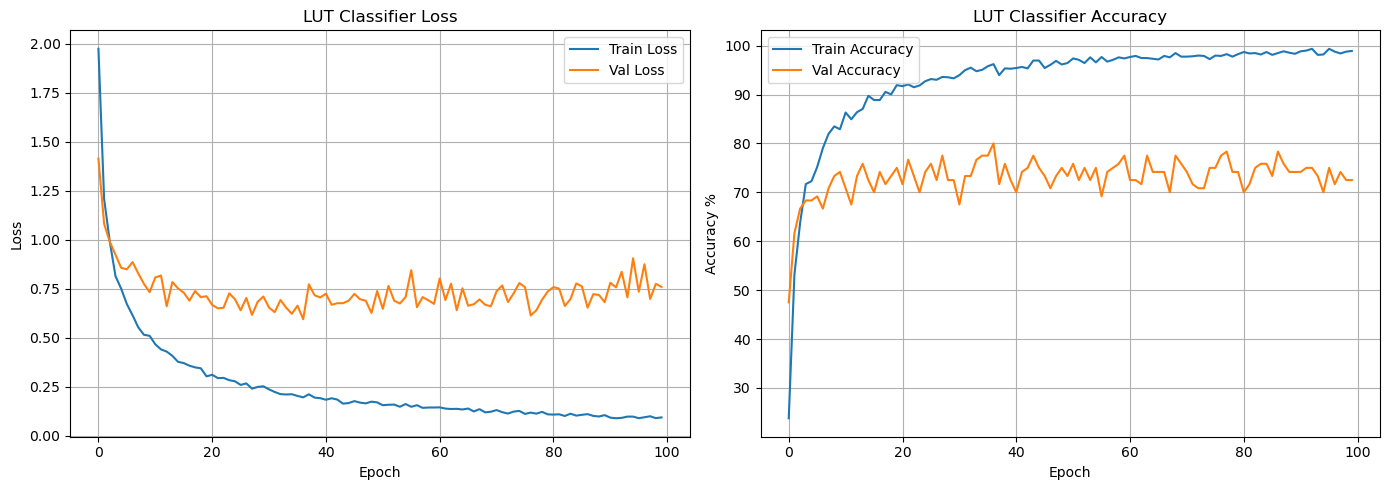

In [122]:
# Initialize LUT classifier
cfg = LUTClassifierConfig()

classifier = LUTClassifier(cfg, table_dropout = 0.25)

# Train
print("Training LUT Classifier on CNN features...")
train_losses, val_losses, train_accs, val_accs = train_lut_classifier(
    classifier,
    train_features,
    train_labels,
    val_features,
    val_labels,
    num_epochs  = 100,
    eval_every  = 5
)

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, label='Train Loss')
ax1.plot(val_losses,   label='Val Loss')
ax1.set_title('LUT Classifier Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(train_accs, label='Train Accuracy')
ax2.plot(val_accs,   label='Val Accuracy')
ax2.set_title('LUT Classifier Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy %')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [440]:
def compute_overlap_count(kernel_size, H_out, W_out, pad):
    """
    Compute how many patches each pixel contributes to
    without looping
    """
    count_pad = np.zeros((1,
                          H_out + 2*pad,
                          W_out + 2*pad))

    # Each output position (i,j) covers a kernel_size x kernel_size region
    # We can compute this with a convolution of ones
    ones = np.ones((1, H_out, W_out))

    for i in range(H_out):
        for j in range(W_out):
            count_pad[0, i:i+kernel_size,
                         j:j+kernel_size] += 1.0

    return np.maximum(count_pad, 1.0)

In [441]:
# Fully lut entire convolutional neural network
'''
Each layer contains a LUT that is applied to each patch in the input. It flattens the patch and then
applies a normal lut to it comparing different values in the patch to create an index and then outputting
a vector from the table of size output channels.

Backwards i need to spend time to understand
'''

@dataclass
class LUTConvLayer:
    in_channels:   int
    out_channels:  int
    kernel_size:   int
    n_tables:      int
    n_comparisons: int
    rng:           np.random.Generator
    
    patch_dim:     int        = field(init=False)
    lut:           LUT        = field(init=False)
    all_caches:    list       = field(default_factory=list, init=False)
    input_padded:  np.ndarray = field(init=False)
    j_all:         np.ndarray = field(init=False)
    rmin_all:      np.ndarray = field(init=False)
    umin_all:      np.ndarray = field(init=False)
    patches:       np.ndarray = field(init=False)
    H_out:         int        = field(init=False)
    W_out:         int        = field(init=False)
    c_pad_cache:   np.ndarray = field(init=False)

    def __post_init__(self):
        self.patch_dim = self.kernel_size * self.kernel_size * self.in_channels
        self.lut       = LUT(
            input_dim        = self.patch_dim,
            output_dim       = self.out_channels,
            n_tables         = self.n_tables,
            n_comparisons    = self.n_comparisons,
            total_index_bits = self.n_comparisons,
            rng              = self.rng,
        )
        self.c_pad_cache = np.zeros(1)

    def im2col_vectorized(self, x_pad, H_out, W_out):
        from numpy.lib.stride_tricks import as_strided
        C  = self.in_channels
        ks = self.kernel_size
        shape   = (H_out, W_out, C, ks, ks)
        s       = x_pad.strides
        strides = (s[1], s[2], s[0], s[1], s[2])
        patches = as_strided(x_pad, shape=shape, strides=strides)
        return patches.reshape(H_out * W_out, C * ks * ks).copy()

    def forward(self, x: np.ndarray) -> np.ndarray:
        """Vectorized forward - replaces old forward"""
        C, H, W      = x.shape
        pad          = self.kernel_size // 2
        H_out, W_out = H, W
        n_patches    = H_out * W_out
        
        x_pad             = np.pad(x, ((0,0),(pad,pad),(pad,pad)), mode='constant')
        self.input_padded = x_pad.copy()
        
        # Extract all patches at once
        patches      = self.im2col_vectorized(x_pad, H_out, W_out)
        self.patches = patches
        
        # All comparisons at once
        vals_a       = patches[:, self.lut.anchors_a]
        vals_b       = patches[:, self.lut.anchors_b]
        diffs        = vals_a - vals_b
        
        # Binary indices for all patches
        powers       = (1 << np.arange(self.lut.n_comparisons))
        bits         = (diffs > 0).astype(np.int64)
        j_all        = (bits * powers[None, None, :]).sum(axis=2)
        
        # r_min and u_min for all patches
        abs_diffs    = np.abs(diffs)
        rmin_all     = abs_diffs.argmin(axis=2)
        umin_all     = diffs[
            np.arange(n_patches)[:, None],
            np.arange(self.lut.n_tables)[None, :],
            rmin_all
        ]
        
        # Table lookup for all patches
        table_idx    = np.arange(self.lut.n_tables)[None, :]
        selected     = self.lut.S[table_idx, j_all, :]
        out_flat     = selected.sum(axis=1)
        
        # Store for backward
        self.j_all    = j_all
        self.rmin_all = rmin_all
        self.umin_all = umin_all
        self.H_out    = H_out
        self.W_out    = W_out
        
        # Build cache list
        self.all_caches = [
            LUTCache(j=j_all[p], r_min=rmin_all[p], u_min=umin_all[p])
            for p in range(n_patches)
        ]
        
        if not np.any(self.c_pad_cache):
            self.c_pad_cache    = compute_overlap_count(self.kernel_size, H_out, W_out, self.kernel_size//2)
        
        out = out_flat.reshape(H_out, W_out, self.out_channels)
        return out.transpose(2, 0, 1)

    def backward(self, grad_out: np.ndarray,
                 learning_rate: float) -> np.ndarray:
        """Vectorized backward - replaces old backward"""
        return self.backward_vectorized(grad_out, learning_rate)
    
    def backward_vectorized(self, grad_out, learning_rate):
        """
        Process ALL patches simultaneously
        instead of looping through each patch
        """
        pad         = self.kernel_size // 2
        n_patches   = self.H_out * self.W_out

        # grad_out: (out_channels, H_out, W_out)
        # -> grad_flat: (n_patches, out_channels)
        grad_flat   = grad_out.transpose(1, 2, 0).reshape(
            n_patches, self.out_channels
        )

        # Extract cached values for ALL patches at once
        # all_caches is list of LUTCache, one per patch

        # Stack all cache arrays
        # j:     (n_patches, n_tables)
        # r_min: (n_patches, n_tables)
        # u_min: (n_patches, n_tables)
        j_all    = np.stack([c.j     for c in self.all_caches])  # (n_patches, n_tables)
        rmin_all = np.stack([c.r_min for c in self.all_caches])  # (n_patches, n_tables)
        umin_all = np.stack([c.u_min for c in self.all_caches])  # (n_patches, n_tables)

        # Compute jbar for ALL patches and ALL tables
        jbar_all = j_all ^ (1 << rmin_all)   # (n_patches, n_tables)

        # Get S values for all patches and tables
        # S shape: (n_tables, table_size, out_channels)
        patch_idx  = np.arange(n_patches)[:, None]          # (n_patches, 1)
        table_idx  = np.arange(self.n_tables)[None, :]      # (1, n_tables)

        # S_j[p, t]    = S[t, j[p,t]]     shape (n_patches, n_tables, out_channels)
        S_j    = self.lut.S[table_idx, j_all,    :]  # (n_patches, n_tables, out_channels)
        S_jbar = self.lut.S[table_idx, jbar_all, :]  # (n_patches, n_tables, out_channels)

        # gi[p, t] = grad_flat[p] dot (S_jbar[p,t] - S_j[p,t])
        diff   = S_jbar - S_j                        # (n_patches, n_tables, out_channels)
        
        # Normalize diff before computing gi
        # this decouples S magnitude from gradient magnitude
        diff_norm    = np.linalg.norm(diff, axis=2, keepdims=True) + 1e-8
        diff_normalized = diff / diff_norm                # unit vectors

        # grad_flat: (n_patches, out_channels)
        # diff:      (n_patches, n_tables, out_channels)
        # gi:        (n_patches, n_tables)
        gi_all = np.einsum('po,pto->pt', grad_flat, diff)

        # Up(u_min) for all patches and tables
        signs        = np.sign(umin_all)
        signs[signs == 0] = 1.0
        Up_all       = -0.5 * signs / ((1.0 + np.abs(umin_all)) ** 2)

        # v[p, t] = gi[p,t] * Up[p,t]
        v_all        = gi_all * Up_all               # (n_patches, n_tables)
        
        # Amplify gradient signal
        #surrogate_scale = 20.0 / np.sqrt(self.lut.n_tables)
        #v_all           = v_all * surrogate_scale

        # Get anchor indices for all patches and tables
        # anchors_a: (n_tables, n_comparisons)
        # rmin_all:  (n_patches, n_tables)
        a_all = self.lut.anchors_a[table_idx, rmin_all]  # (n_patches, n_tables)
        b_all = self.lut.anchors_b[table_idx, rmin_all]  # (n_patches, n_tables)

        # Build patch gradients
        # grad_patches: (n_patches, patch_dim)
        grad_patches = np.zeros((n_patches, self.patch_dim))

        for t in range(self.n_tables):
            np.add.at(grad_patches,
                      (np.arange(n_patches), a_all[:, t]),
                       v_all[:, t])
            np.add.at(grad_patches,
                      (np.arange(n_patches), b_all[:, t]),
                      -v_all[:, t])

        # Update S rows for all patches and tables at once
        # S[t, j[p,t]] -= lr * grad_flat[p]  for all p, t
        for t in range(self.n_tables):
            np.add.at(
                self.lut.S[t],           # (table_size, out_channels)
                j_all[:, t],             # indices to update
                -learning_rate * grad_flat  # updates (n_patches, out_channels)
            )

        # Scatter patch gradients back to spatial grad_in
        grad_in_pad = np.zeros((self.in_channels,
                                self.H_out + 2*pad,
                                self.W_out + 2*pad))

        # grad_patches: (n_patches, patch_dim)
        # reshape to   (n_patches, in_channels, kernel_size, kernel_size)
        grad_patches_spatial = grad_patches.reshape(
            n_patches, self.in_channels,
            self.kernel_size, self.kernel_size
        )

        # Scatter back to padded gradient
        for idx in range(n_patches):
            i = idx // self.W_out
            j = idx  % self.W_out
            grad_in_pad[:, i:i+self.kernel_size,
                           j:j+self.kernel_size] += grad_patches_spatial[idx]
            
        # Divide by count to normalize accumulation
        count_pad    = np.maximum(self.c_pad_cache, 1.0)   # avoid division by zero
        grad_in_pad  = grad_in_pad / count_pad

        if pad > 0:
            return grad_in_pad[:, pad:-pad, pad:-pad]
        return grad_in_pad
    
    def backward_slow(self, grad_out: np.ndarray,
                 learning_rate: float) -> np.ndarray:
        pad      = self.kernel_size // 2
        C, H, W  = (self.in_channels,
                    self.H_out + 2*pad,
                    self.W_out + 2*pad)
        
        grad_in_pad = np.zeros((C, H, W))
        
        # grad_out shape: (out_channels, H_out, W_out)
        grad_flat = grad_out.transpose(1, 2, 0).reshape(-1, self.out_channels)
        
        for idx, (cache, patch_grad_out) in enumerate(
            zip(self.all_caches, grad_flat)
        ):
            patch_grad = self.lut.backward_from_cache(
                cache, patch_grad_out, learning_rate
            )
            i = idx // self.W_out
            j = idx  % self.W_out
            grad_in_pad[:, i:i+self.kernel_size,
                           j:j+self.kernel_size] += patch_grad.reshape(
                self.in_channels, self.kernel_size, self.kernel_size
            )
        
        if pad > 0:
            return grad_in_pad[:, pad:-pad, pad:-pad]
        return grad_in_padn

@dataclass
class PartialResidualLUTConvLayer:
    """
    LUT Conv with partial residual connection
    
    First in_channels of output:
        output = input + LUT[:in_channels]
        preserves existing information
    
    Remaining (out_channels - in_channels):
        output = LUT[in_channels:]
        learns completely new features
    
    Requires out_channels >= in_channels
    """
    in_channels:   int
    out_channels:  int    # must be >= in_channels
    kernel_size:   int
    n_tables:      int
    n_comparisons: int
    rng:           np.random.Generator
    
    patch_dim:     int        = field(init=False)
    lut:           LUT        = field(init=False)
    all_caches:    list       = field(default_factory=list, init=False)
    input_padded:  np.ndarray = field(init=False)
    j_all:         np.ndarray = field(init=False)
    rmin_all:      np.ndarray = field(init=False)
    umin_all:      np.ndarray = field(init=False)
    patches:       np.ndarray = field(init=False)
    H_out:         int        = field(init=False)
    W_out:         int        = field(init=False)
    input_cache:   np.ndarray = field(init=False)

    def __post_init__(self):
        assert self.out_channels >= self.in_channels, \
            f"out_channels ({self.out_channels}) must be >= " \
            f"in_channels ({self.in_channels})"
        
        self.patch_dim = self.kernel_size ** 2 * self.in_channels
        self.lut       = LUT(
            input_dim        = self.patch_dim,
            output_dim       = self.out_channels,  # full output
            n_tables         = self.n_tables,
            n_comparisons    = self.n_comparisons,
            total_index_bits = self.n_comparisons,
            rng              = self.rng
        )
        
        new_channels = self.out_channels - self.in_channels
        print(f"  PartialResidualLUTConv: "
              f"{self.in_channels} -> {self.out_channels} channels")
        print(f"    Residual channels: {self.in_channels} "
              f"(input + LUT correction)")
        print(f"    New channels:      {new_channels} "
              f"(LUT output only)")

    def im2col_vectorized(self, x_pad, H_out, W_out):
        from numpy.lib.stride_tricks import as_strided
        C       = self.in_channels
        ks      = self.kernel_size
        shape   = (H_out, W_out, C, ks, ks)
        s       = x_pad.strides
        strides = (s[1], s[2], s[0], s[1], s[2])
        patches = as_strided(x_pad, shape=shape, strides=strides)
        return patches.reshape(H_out * W_out, C * ks * ks).copy()

    def forward(self, x: np.ndarray) -> np.ndarray:
        """
        Args:
            x: shape (in_channels, H, W)
        Returns:
            out: shape (out_channels, H, W)
                 first in_channels:  x + LUT[:in_channels]
                 remaining channels: LUT[in_channels:]
        """
        C, H, W      = x.shape
        pad          = self.kernel_size // 2
        H_out, W_out = H, W
        n_patches    = H_out * W_out
        
        # Cache input for residual
        self.input_cache = x.copy()
        
        # Pad and extract patches
        x_pad             = np.pad(
            x, ((0,0),(pad,pad),(pad,pad)), mode='constant'
        )
        self.input_padded = x_pad.copy()
        patches           = self.im2col_vectorized(x_pad, H_out, W_out)
        self.patches      = patches
        
        # Binary comparisons
        vals_a   = patches[:, self.lut.anchors_a]
        vals_b   = patches[:, self.lut.anchors_b]
        diffs    = vals_a - vals_b
        
        powers   = (1 << np.arange(self.lut.n_comparisons))
        bits     = (diffs > 0).astype(np.int64)
        j_all    = (bits * powers[None, None, :]).sum(axis=2)
        
        abs_diffs = np.abs(diffs)
        rmin_all  = abs_diffs.argmin(axis=2)
        umin_all  = diffs[
            np.arange(n_patches)[:, None],
            np.arange(self.lut.n_tables)[None, :],
            rmin_all
        ]
        
        # Table lookup -> (n_patches, out_channels)
        table_idx    = np.arange(self.lut.n_tables)[None, :]
        selected     = self.lut.S[table_idx, j_all, :]
        lut_out_flat = selected.sum(axis=1)
        
        # Store for backward
        self.j_all    = j_all
        self.rmin_all = rmin_all
        self.umin_all = umin_all
        self.H_out    = H_out
        self.W_out    = W_out
        
        self.all_caches = [
            LUTCache(j=j_all[p], r_min=rmin_all[p], u_min=umin_all[p])
            for p in range(n_patches)
        ]
        
        # Reshape to spatial (H, W, out_channels)
        lut_out = lut_out_flat.reshape(H_out, W_out, self.out_channels)
        lut_out = lut_out.transpose(2, 0, 1)   # (out_channels, H, W)
        
        # Build output
        out = np.zeros((self.out_channels, H_out, W_out))
        
        # First in_channels: residual connection
        # output = input + LUT correction
        out[:self.in_channels] = x + lut_out[:self.in_channels]  # ✅
        
        # Remaining channels: new features
        # output = LUT output only
        out[self.in_channels:] = lut_out[self.in_channels:]       # ✅
        
        return out

    def backward(self, grad_out: np.ndarray,
                 learning_rate: float) -> np.ndarray:
        """
        Backward through partial residual
        
        For residual channels:
            d_input   = grad_out[:in_channels]  (identity branch)
            d_lut[:in_channels] = grad_out[:in_channels]
        
        For new channels:
            d_lut[in_channels:] = grad_out[in_channels:]
        
        Combined:
            d_lut = grad_out  (all channels)
            d_input = grad_out[:in_channels]  (only residual channels)
        """
        pad       = self.kernel_size // 2
        n_patches = self.H_out * self.W_out
        
        # Gradient for LUT: all output channels contribute
        grad_lut_flat = grad_out.transpose(1, 2, 0).reshape(
            n_patches, self.out_channels
        )
        
        # Gradient for input: only residual channels
        # (identity branch only exists for first in_channels)
        grad_identity = grad_out[:self.in_channels]   # (in_channels, H, W)
        
        # LUT backward
        j_all    = self.j_all
        rmin_all = self.rmin_all
        umin_all = self.umin_all
        jbar_all = j_all ^ (1 << rmin_all)
        
        table_idx = np.arange(self.lut.n_tables)[None, :]
        S_j       = self.lut.S[table_idx, j_all,    :]
        S_jbar    = self.lut.S[table_idx, jbar_all, :]
        
        diff      = S_jbar - S_j
        diff_norm = np.linalg.norm(diff, axis=2, keepdims=True) + 1e-8
        diff_normalized = diff / diff_norm
        
        # gi uses full out_channels gradient
        gi_all    = np.einsum('po,pto->pt', grad_lut_flat, diff_normalized)
        
        signs     = np.sign(umin_all)
        signs[signs == 0] = 1.0
        Up_all    = -0.5 * signs / ((1.0 + np.abs(umin_all)) ** 2)
        v_all     = gi_all * Up_all
        
        #surrogate_scale = 5.0 / self.lut.n_tables
        #v_all           = v_all * surrogate_scale
        
        table_idx_1d = np.arange(self.lut.n_tables)
        a_all     = self.lut.anchors_a[table_idx_1d, rmin_all]
        b_all     = self.lut.anchors_b[table_idx_1d, rmin_all]
        
        grad_patches = np.zeros((n_patches, self.patch_dim))
        for t in range(self.lut.n_tables):
            np.add.at(grad_patches,
                      (np.arange(n_patches), a_all[:, t]),
                       v_all[:, t])
            np.add.at(grad_patches,
                      (np.arange(n_patches), b_all[:, t]),
                      -v_all[:, t])
        
        # Build combined lr-scaled gradient
        #scaled_grad    = grad_lut_flat.copy()
        #scaled_grad[:, self.in_channels:] *= 5.0   # boost new channels
        
        # Update S tables
        for t in range(self.lut.n_tables):
            np.add.at(
                self.lut.S[t],
                j_all[:, t],
                -learning_rate * grad_lut_flat
            )
        
        # Scatter patch gradients back
        grad_patches_spatial = grad_patches.reshape(
            n_patches, self.in_channels,
            self.kernel_size, self.kernel_size
        )
        
        grad_in_pad  = np.zeros((self.in_channels,
                                 self.H_out + 2*pad,
                                 self.W_out + 2*pad))
        count_pad    = np.zeros((1,
                                 self.H_out + 2*pad,
                                 self.W_out + 2*pad))
        
        for idx in range(n_patches):
            i = idx // self.W_out
            j = idx  % self.W_out
            grad_in_pad[:, i:i+self.kernel_size,
                           j:j+self.kernel_size] += \
                grad_patches_spatial[idx]
            count_pad[0,  i:i+self.kernel_size,
                           j:j+self.kernel_size] += 1.0
        
        count_pad   = np.maximum(count_pad, 1.0)
        grad_lut_in = grad_in_pad / count_pad
        
        if pad > 0:
            grad_lut_in = grad_lut_in[:, pad:-pad, pad:-pad]
        
        # Total input gradient:
        # identity branch + lut branch
        # both only exist for first in_channels
        grad_in = grad_identity + grad_lut_in   # (in_channels, H, W)
        
        return grad_in    

@dataclass
class LUTPoolLayer:
    """
    Max pooling has no parameters so we can keep it as is
    Just implemented in numpy
    """
    pool_size: int = 2
    
    # Cache for backward
    max_indices: np.ndarray = field(init=False)
    input_shape: tuple      = field(init=False)
    
    def forward(self, x: np.ndarray) -> np.ndarray:
        """
        Args:
            x: shape (C, H, W)
        Returns:
            out: shape (C, H//pool, W//pool)
        """
        C, H, W       = x.shape
        self.input_shape = x.shape
        H_out         = H // self.pool_size
        W_out         = W // self.pool_size
        out           = np.zeros((C, H_out, W_out))
        self.max_indices = np.zeros((C, H_out, W_out, 2), dtype=np.int64)
        
        for c in range(C):
            for i in range(H_out):
                for j in range(W_out):
                    patch = x[c,
                               i*self.pool_size:(i+1)*self.pool_size,
                               j*self.pool_size:(j+1)*self.pool_size]
                    
                    idx             = np.unravel_index(np.argmax(patch), patch.shape)
                    out[c, i, j]    = patch[idx]
                    self.max_indices[c, i, j] = [
                        i*self.pool_size + idx[0],
                        j*self.pool_size + idx[1]
                    ]
        return out
    
    def backward(self, grad_out: np.ndarray) -> np.ndarray:
        """Route gradients back to max locations"""
        grad_in = np.zeros(self.input_shape)
        C, H_out, W_out = grad_out.shape
        
        for c in range(C):
            for i in range(H_out):
                for j in range(W_out):
                    hi, wi = self.max_indices[c, i, j]
                    grad_in[c, hi, wi] += grad_out[c, i, j]
        
        return grad_in
    
    
@dataclass
class LUTBatchNorm:
    """
    Simple batch norm in numpy
    Keeps features well distributed for LUT comparisons
    This is critical - without it LUT comparisons become meaningless
    """
    num_channels: int
    eps:          float = 1e-5
    momentum:     float = 0.1
    gamma_max:    float = 2.0
    
    gamma:        np.ndarray = field(init=False)
    beta:         np.ndarray = field(init=False)
    running_mean: np.ndarray = field(init=False)
    running_var:  np.ndarray = field(init=False)
    
    # Cache for backward
    x_norm:       np.ndarray = field(init=False)
    std:          np.ndarray = field(init=False)
    
    def __post_init__(self):
        self.gamma        = np.ones(self.num_channels)
        self.beta         = np.zeros(self.num_channels)
        self.running_mean = np.zeros(self.num_channels)
        self.running_var  = np.ones(self.num_channels)
    
    def forward(self, x: np.ndarray, training: bool = True) -> np.ndarray:
        """x: shape (C, H, W)"""
        if training:
            mean          = x.mean(axis=(1,2))
            var           = x.var(axis=(1,2))
            self.std      = np.sqrt(var + self.eps)
            self.x_norm   = (x - mean[:,None,None]) / self.std[:,None,None]
            
            self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * mean
            self.running_var  = (1 - self.momentum) * self.running_var  + self.momentum * var
        else:
            std           = np.sqrt(self.running_var + self.eps)
            self.x_norm   = (x - self.running_mean[:,None,None]) / std[:,None,None]
        
        return self.gamma[:,None,None] * self.x_norm + self.beta[:,None,None]
    
    def backward(self, grad_out, learning_rate):
        C, H, W  = grad_out.shape
        N        = H * W
        
        dgamma   = (grad_out * self.x_norm).sum(axis=(1,2))
        dbeta    = grad_out.sum(axis=(1,2))
        
        dx_norm  = grad_out * self.gamma[:,None,None]
        dx       = (1/N) / self.std[:,None,None] * (
            N * dx_norm
            - dx_norm.sum(axis=(1,2), keepdims=True)
            - self.x_norm * (dx_norm * self.x_norm).sum(axis=(1,2), keepdims=True)
        )
        
        self.gamma -= learning_rate * dgamma
        self.beta  -= learning_rate * dbeta
        
        # Clip gamma to prevent explosion
        self.gamma = np.clip(self.gamma, -self.gamma_max, self.gamma_max)
        
        return dx
    

@dataclass
class LUTFruitCNN:
    """
    Full LUT based CNN for fruit classification
    
    Architecture:
        LUTConv(3,  16) -> BN -> ReLU -> Pool
        LUTConv(16, 32) -> BN -> ReLU -> Pool
        LUTConv(32, 64) -> BN -> ReLU -> Pool
        Flatten
        LUT Classifier -> 6 classes
    """
    num_classes:   int
    n_tables:      int   = 8
    n_comparisons: int   = 4
    seed:          int   = 0
    
    rng:           np.random.Generator = field(init=False)
    
    # Conv blocks
    conv1:         LUTConvLayer  = field(init=False)
    bn1:           LUTBatchNorm  = field(init=False)
    pool1:         LUTPoolLayer  = field(init=False)
    '''
    conv2:         LUTConvLayer  = field(init=False)
    bn2:           LUTBatchNorm  = field(init=False)
    pool2:         LUTPoolLayer  = field(init=False)
    
    conv3:         LUTConvLayer  = field(init=False)
    bn3:           LUTBatchNorm  = field(init=False)
    pool3:         LUTPoolLayer  = field(init=False)
    '''
    # Classifier
    classifier:    LUTClassifier = field(init=False)
    
    # Cache
    training:      bool          = True
    feature_shape: tuple         = field(init=False)

    def __post_init__(self):
        self.rng   = np.random.default_rng(self.seed)
        
        # Block 1: 3 -> 8 channels
        self.conv1 = LUTConvLayer(3,  8, kernel_size=3,
                                  n_tables=self.n_tables,
                                  n_comparisons=self.n_comparisons,
                                  rng=self.rng)
        self.bn1   = LUTBatchNorm(8)
        self.pool1 = LUTPoolLayer(2)
        '''
        # Block 2: 8 -> 16 channels
        self.conv2 = LUTConvLayer(8, 8, kernel_size=3,
                                  n_tables=self.n_tables,
                                  n_comparisons=self.n_comparisons,
                                  rng=self.rng)
        self.bn2   = LUTBatchNorm(8)
        self.pool2 = LUTPoolLayer(2)
        
        # Block 3: 16 -> 16 channels
        self.conv3 = LUTConvLayer(16, 16, kernel_size=3,
                                  n_tables=self.n_tables,
                                  n_comparisons=self.n_comparisons,
                                  rng=self.rng)
        self.bn3   = LUTBatchNorm(16)
        self.pool3 = LUTPoolLayer(2)
        '''
        # LUT Classifier
        # For 32x32 input: after 1 pools -> 16x16 spatial
        # 8 channels * 16 * 16 = 2048

        cfg = LUTClassifierConfig(
            input_dim     = 2048,
            hidden_dim    = 64,
            num_classes   = self.num_classes,
            n_tables      = self.n_tables,
            n_comparisons = self.n_comparisons,
            seed          = self.seed
        )
        self.classifier = LUTClassifier(cfg)
        
        print("LUT CNN initialized")
        print(f"  n_tables:      {self.n_tables}")
        print(f"  n_comparisons: {self.n_comparisons}")

    def forward(self, x):
        
        # Block 1
        x = self.conv1.forward(x)
        x = np.maximum(0, x)
        self.relu1_mask = (x > 0)
        # normalize activations manually instead of BN
        x = self.normalize_activations(x)
        x = self.pool1.forward(x)
        '''
        # Block 2
        x = self.conv2.forward(x)
        x = np.maximum(0, x)
        self.relu2_mask = (x > 0)
        x = self.normalize_activations(x)
        x = self.pool2.forward(x)
        
        # Block 3
        x = self.conv3.forward(x)
        x = np.maximum(0, x)
        self.relu3_mask = (x > 0)
        x = self.normalize_activations(x)
        x = self.pool3.forward(x)
        '''
        self.feature_shape = x.shape
        logits = self.classifier.forward(x.flatten())
        return logits

    def normalize_activations(self, x):
        """
        Simple per-channel normalization
        no learned parameters = no backward issues
        """
        mean = x.mean(axis=(1,2), keepdims=True)
        std  = x.std(axis=(1,2),  keepdims=True) + 1e-8
        return (x - mean) / std

    def backward(self, logits_grad, learning_rate):

        x_flat_grad = self.classifier.backward(logits_grad, learning_rate)
        x_grad      = x_flat_grad.reshape(self.feature_shape)
        '''
        # Block 3 - no BN backward needed
        x_grad      = self.pool3.backward(x_grad)
        x_grad      = x_grad * self.relu3_mask
        x_grad      = self.conv3.backward(x_grad, learning_rate)
        
        # Block 2
        x_grad      = self.pool2.backward(x_grad)
        x_grad      = x_grad * self.relu2_mask
        x_grad      = self.conv2.backward(x_grad, learning_rate*0.5)
        '''
        # Block 1
        x_grad      = self.pool1.backward(x_grad)
        x_grad      = x_grad * self.relu1_mask
        x_grad      = self.conv1.backward(x_grad, learning_rate*0.1)      
        

In [442]:
# save model

import pickle
import os
from datetime import datetime

def get_lut_state_dict(model) -> dict:
    """
    Extract all learnable parameters from LUTFruitCNN
    Equivalent to PyTorch model.state_dict()
    
    Returns:
        state_dict: dictionary of all parameters
    """
    state_dict = {

        'config': {
            'num_classes':   model.num_classes,
            'n_tables':      model.n_tables,
            'n_comparisons': model.n_comparisons,
            'seed':          model.seed,
        },
        
        'conv1': {
            'S':         model.conv1.lut.S.copy(),
            'anchors_a': model.conv1.lut.anchors_a.copy(),
            'anchors_b': model.conv1.lut.anchors_b.copy(),
        },
        
        'classifier': {
            'W_proj':       model.classifier.W_proj.copy(),
            'hidden_lut': {
                'S':         model.classifier.hidden_lut.S.copy(),
                'anchors_a': model.classifier.hidden_lut.anchors_a.copy(),
                'anchors_b': model.classifier.hidden_lut.anchors_b.copy(),
            },
            'output_lut': {
                'S':         model.classifier.output_lut.S.copy(),
                'anchors_a': model.classifier.output_lut.anchors_a.copy(),
                'anchors_b': model.classifier.output_lut.anchors_b.copy(),
            },
        },
        
        'metadata': {
            'saved_at':    datetime.now().isoformat(),
            'input_shape': (3, 32, 32),
        }
    }
    
    return state_dict

def load_lut_state_dict(model, state_dict: dict) -> None:
    """
    Load parameters into LUTFruitCNN
    Equivalent to PyTorch model.load_state_dict()
    
    Args:
        model:      LUTFruitCNN instance
        state_dict: dictionary from get_lut_state_dict
    """
    # Conv layers
    for layer_name in ['conv1']: #, 'conv2', 'conv3']:
        layer     = getattr(model, layer_name)
        sd        = state_dict[layer_name]
        layer.lut.S         = sd['S'].copy()
        layer.lut.anchors_a = sd['anchors_a'].copy()
        layer.lut.anchors_b = sd['anchors_b'].copy()
    
    # Classifier
    clf_sd = state_dict['classifier']
    model.classifier.W_proj = clf_sd['W_proj'].copy()
    
    model.classifier.hidden_lut.S         = clf_sd['hidden_lut']['S'].copy()
    model.classifier.hidden_lut.anchors_a = clf_sd['hidden_lut']['anchors_a'].copy()
    model.classifier.hidden_lut.anchors_b = clf_sd['hidden_lut']['anchors_b'].copy()
    
    model.classifier.output_lut.S         = clf_sd['output_lut']['S'].copy()
    model.classifier.output_lut.anchors_a = clf_sd['output_lut']['anchors_a'].copy()
    model.classifier.output_lut.anchors_b = clf_sd['output_lut']['anchors_b'].copy()
    
    print(f"Model loaded successfully")
    print(f"  Saved at: {state_dict['metadata']['saved_at']}")

def save_lut_model(model, path: str, history) -> None:
    """
    Save LUTFruitCNN to file
    Equivalent to torch.save(model.state_dict(), path)
    
    Args:
        model: LUTFruitCNN instance
        path:  file path to save to e.g. 'models/lut_model.pkl'
    """
    # Create directory if needed
    os.makedirs(os.path.dirname(path) if os.path.dirname(path) else '.', 
                exist_ok=True)
    
    state_dict = get_lut_state_dict(model)
    
    with open(path, 'wb') as f:
        pickle.dump(state_dict, f)
    
    # Show file size
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"Model saved to: {path}")
    print(f"File size:      {size_mb:.2f} MB")

def load_lut_model(path: str, model=None) -> object:
    """
    Load LUTFruitCNN from file
    Equivalent to model.load_state_dict(torch.load(path))
    
    Args:
        path:  file path to load from
        model: existing LUTFruitCNN instance to load into
               if None, creates new model from saved config
    
    Returns:
        model: LUTFruitCNN with loaded parameters
    """
    with open(path, 'rb') as f:
        state_dict = pickle.load(f)
    
    if model is None:
        cfg   = state_dict['config']
        model = LUTFruitCNN(
            num_classes   = cfg['num_classes'],
            n_tables      = cfg['n_tables'],
            n_comparisons = cfg['n_comparisons'],
            seed          = cfg['seed']
        )
    
    load_lut_state_dict(model, state_dict)
    return model

In [443]:
def image_to_numpy(image_path, size=32):
    """Load image and convert to numpy array normalized to [-1, 1]"""
    img    = Image.open(image_path).convert('RGB').resize((size, size))
    arr    = np.array(img).astype(np.float32) / 127.5 - 1.0
    return arr.transpose(2, 0, 1)   # (H,W,C) -> (C,H,W)

def image_lr_schedule(epoch: int, 
                      base_lr: float   = 0.001,
                      decay:   float   = 0.95) -> float:
    """Simple exponential decay schedule"""
    return base_lr * (decay ** epoch)

def preprocess_for_lut(img_tensor: torch.Tensor) -> np.ndarray:
    """
    Convert tensor to numpy and normalize per image
    so LUT comparisons are meaningful
    """
    x    = img_tensor.numpy()   # (3, H, W)
    
    # Normalize each channel to [-1, 1]
    for c in range(x.shape[0]):
        ch   = x[c]
        mean = ch.mean()
        std  = ch.std() + 1e-8
        x[c] = (ch - mean) / std
    
    return x


def train_lut_cnn(model, train_loader, val_loader,
                  pth, num_epochs=30, device=None):
    
    print("training")
    
    # Detect model type for correct save function
    if isinstance(model, LUTFruitCNN_3Layer):
        save_fn = save_3layer_model
    elif isinstance(model, LUTFruitCNN_Extended):
        save_fn = save_ext_model
    else:
        save_fn = save_lut_model
    
    best_val_acc  = 0.0
    best_val_loss = float('inf')
    best_train_loss = float('inf')
    
    history = {
        'train_acc':  [],
        'val_acc':    [],
        'train_loss': [],
        'val_loss':   [],
        'epochs':     []
    }
    
    for epoch in range(1, num_epochs + 1):
        
        model.training = True
        correct        = 0
        total          = 0
        epoch_loss     = 0.0
        lr             = image_lr_schedule(epoch)
        
        for images, labels in train_loader:
            for img_tensor, label in zip(images, labels):
                x      = preprocess_for_lut(img_tensor)
                target = label.item()
                
                logits = model.forward(x)
                loss, logits_grad = cross_entropy_from_logits(
                    logits, target
                )
                epoch_loss += loss
                
                if np.argmax(logits) == target:
                    correct += 1
                total += 1
                
                model.backward(logits_grad, lr)
        
        avg_train_loss = epoch_loss / total
        train_acc      = 100 * correct / total
        
        model.training = False
        val_correct    = 0
        val_total      = 0
        val_loss       = 0.0
        
        for images, labels in val_loader:
            for img_tensor, label in zip(images, labels):
                x      = preprocess_for_lut(img_tensor)
                target = label.item()
                logits = model.forward(x)
                loss, _ = cross_entropy_from_logits(logits, target)
                val_loss   += loss
                if np.argmax(logits) == target:
                    val_correct += 1
                val_total += 1
        
        avg_val_loss = val_loss / val_total
        val_acc      = 100 * val_correct / val_total
        
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['epochs'].append(epoch)
        
        print(f"Epoch [{epoch}/{num_epochs}]  "
              f"LR: {lr:.5f}  "
              f"Train Loss: {avg_train_loss:.4f}  "
              f"Train Acc: {train_acc:.1f}%  "
              f"Val Loss: {avg_val_loss:.4f}  "
              f"Val Acc: {val_acc:.1f}%")
        
        if avg_train_loss < best_train_loss:
            best_val_acc  = val_acc
            best_val_loss = avg_val_loss
            best_train_loss = avg_train_loss
            save_fn(model, pth, history=history)
            print(f"  -> Best model saved: "
                  f"val_acc={best_val_acc:.1f}%  "
                  f"val_loss={best_val_loss:.4f}")
    
    plot_training_history(history)
    return history

def plot_training_history(history: dict) -> None:
    """
    Plot training and validation loss and accuracy
    Same style as PyTorch training plots
    """
    epochs = history['epochs']
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Loss plot
    ax1.plot(epochs, history['train_loss'],
             label='Train Loss', color='blue',  marker='o', markersize=3)
    ax1.plot(epochs, history['val_loss'],
             label='Val Loss',   color='orange', marker='o', markersize=3)
    ax1.axhline(y=0.693, color='red', linestyle='--',
                alpha=0.5, label='Random chance loss')
    ax1.set_title('Training vs Validation Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Mark best val loss
    best_epoch = np.argmin(history['val_loss']) + 1
    best_loss  = min(history['val_loss'])
    ax1.axvline(x=best_epoch, color='green',
                linestyle='--', alpha=0.5,
                label=f'Best val loss epoch {best_epoch}')
    ax1.annotate(f'{best_loss:.4f}',
                 xy=(best_epoch, best_loss),
                 xytext=(best_epoch + 1, best_loss + 0.1),
                 color='red', fontsize=9)
    ax1.legend()
    
    # Accuracy plot
    ax2.plot(epochs, history['train_acc'],
             label='Train Acc', color='blue',  marker='o', markersize=3)
    ax2.plot(epochs, history['val_acc'],
             label='Val Acc',   color='orange', marker='o', markersize=3)
    ax2.axhline(y=50, color='red', linestyle='--',
                alpha=0.5, label='Random chance (50%)')
    ax2.set_title('Training vs Validation Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy %')
    ax2.set_ylim(0, 100)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # Mark best val acc
    best_epoch = np.argmax(history['val_acc']) + 1
    best_acc   = max(history['val_acc'])
    ax2.axvline(x=best_epoch, color='green',
                linestyle='--', alpha=0.5,
                label=f'Best val acc epoch {best_epoch}')
    ax2.annotate(f'{best_acc:.1f}%',
                 xy=(best_epoch, best_acc),
                 xytext=(best_epoch + 1, best_acc - 5),
                 color='green', fontsize=9)
    ax2.legend()
    
    plt.suptitle('LUT CNN Training History', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # Print summary
    print(f"\nTraining Summary:")
    print(f"  Best val acc:  {max(history['val_acc']):.1f}%  "
          f"at epoch {np.argmax(history['val_acc']) + 1}")
    print(f"  Best val loss: {min(history['val_loss']):.4f}  "
          f"at epoch {np.argmin(history['val_loss']) + 1}")
    print(f"  Final train acc:  {history['train_acc'][-1]:.1f}%")
    print(f"  Final val acc:    {history['val_acc'][-1]:.1f}%")


def plot_history_from_file(model_path: str) -> None:
    """
    Load a saved model and plot its training history
    if history was saved alongside it
    """
    history_path = model_path.replace('.pkl', '_history.pkl')
    
    if os.path.exists(history_path):
        with open(history_path, 'rb') as f:
            history = pickle.load(f)
        plot_training_history(history)
    else:
        print(f"No history file found at {history_path}")

In [214]:
import time
from collections import defaultdict

def train_lut_cnn_timed(model, twoclasstrain_loader, twoclassval_loader,
                         num_epochs=30, device=None):
    
    print("training")
    
    best_val_acc = 0.0
    
    for epoch in range(1, num_epochs + 1):
        
        epoch_start = time.time()
        
        # Timing accumulators
        times = defaultdict(float)
        
        # Training
        model.training = True
        correct        = 0
        total          = 0
        epoch_loss     = 0.0
        lr             = image_lr_schedule(epoch)
        
        for step, (images, labels) in enumerate(train_loader, start=1):
            for img_tensor, label in zip(images, labels):
                
                # Preprocess timing
                t0     = time.time()
                x      = preprocess_for_lut(img_tensor)
                target = label.item()
                times['preprocess'] += time.time() - t0
                
                # Forward conv timing
                t0     = time.time()
                
                # Block 1 forward
                x_fwd  = model.conv1.forward(x)
                times['forward_conv1'] += time.time() - t0
                
                t0     = time.time()
                x_fwd  = model.bn1.forward(x_fwd, model.training)
                x_fwd  = np.maximum(0, x_fwd)
                x_fwd  = model.pool1.forward(x_fwd)
                times['forward_bn_relu_pool1'] += time.time() - t0
                
                # Block 2 forward
                t0     = time.time()
                x_fwd  = model.conv2.forward(x_fwd)
                times['forward_conv2'] += time.time() - t0
                
                t0     = time.time()
                x_fwd  = model.bn2.forward(x_fwd, model.training)
                x_fwd  = np.maximum(0, x_fwd)
                x_fwd  = model.pool2.forward(x_fwd)
                times['forward_bn_relu_pool2'] += time.time() - t0
                
                # Block 3 forward
                t0     = time.time()
                x_fwd  = model.conv3.forward(x_fwd)
                times['forward_conv3'] += time.time() - t0
                
                t0     = time.time()
                x_fwd  = model.bn3.forward(x_fwd, model.training)
                x_fwd  = np.maximum(0, x_fwd)
                x_fwd  = model.pool3.forward(x_fwd)
                times['forward_bn_relu_pool3'] += time.time() - t0
                
                # Classifier forward
                t0              = time.time()
                model.feature_shape = x_fwd.shape
                logits          = model.classifier.forward(x_fwd.flatten())
                times['forward_classifier'] += time.time() - t0
                
                # Loss
                t0              = time.time()
                loss, logits_grad = cross_entropy_from_logits(logits, target)
                epoch_loss     += loss
                times['loss'] += time.time() - t0
                
                if np.argmax(logits) == target:
                    correct += 1
                total += 1
                
                # ---- BACKWARD ----
                
                # Classifier backward
                t0          = time.time()
                x_flat_grad = model.classifier.backward(logits_grad, lr)
                times['backward_classifier'] += time.time() - t0
                
                x_grad      = x_flat_grad.reshape(model.feature_shape)
                
                # Block 3 backward
                t0          = time.time()
                x_grad      = model.pool3.backward(x_grad)
                x_grad      = x_grad * (x_grad > 0)
                x_grad      = model.bn3.backward(x_grad, lr)
                times['backward_bn_pool3'] += time.time() - t0
                
                t0          = time.time()
                x_grad      = model.conv3.backward(x_grad, lr)
                times['backward_conv3'] += time.time() - t0
                
                # Block 2 backward
                t0          = time.time()
                x_grad      = model.pool2.backward(x_grad)
                x_grad      = x_grad * (x_grad > 0)
                x_grad      = model.bn2.backward(x_grad, lr)
                times['backward_bn_pool2'] += time.time() - t0
                
                t0          = time.time()
                x_grad      = model.conv2.backward(x_grad, lr)
                times['backward_conv2'] += time.time() - t0
                
                # Block 1 backward
                t0          = time.time()
                x_grad      = model.pool1.backward(x_grad)
                x_grad      = x_grad * (x_grad > 0)
                x_grad      = model.bn1.backward(x_grad, lr)
                times['backward_bn_pool1'] += time.time() - t0
                
                t0          = time.time()
                x_grad      = model.conv1.backward(x_grad, lr)
                times['backward_conv1'] += time.time() - t0
        
        train_acc   = 100 * correct / total
        
        # Validation timing
        t0          = time.time()
        model.training = False
        val_correct = 0
        val_total   = 0
        
        for images, labels in val_loader:
            for img_tensor, label in zip(images, labels):
                x      = img_tensor.numpy()
                target = label.item()
                logits = model.forward(x)
                if np.argmax(logits) == target:
                    val_correct += 1
                val_total += 1
        
        val_acc              = 100 * val_correct / val_total
        times['validation']  = time.time() - t0
        epoch_time           = time.time() - epoch_start
        
        # ---- Print timing report ----
        total_timed = sum(times.values())
        
        print(f"\n{'='*55}")
        print(f"Epoch [{epoch}/{num_epochs}]  "
              f"Train: {train_acc:.1f}%  Val: {val_acc:.1f}%")
        print(f"{'='*55}")
        print(f"{'Component':<30} {'Time(s)':>8} {'% Total':>8}")
        print(f"{'-'*55}")
        
        # Sort by time descending so slowest shows first
        for key, t in sorted(times.items(), key=lambda x: -x[1]):
            pct = 100 * t / epoch_time
            print(f"  {key:<28} {t:>8.2f}s {pct:>7.1f}%")
        
        print(f"{'-'*55}")
        print(f"  {'Total epoch':<28} {epoch_time:>8.2f}s {'100.0':>7}%")
        
        # Estimate remaining time
        remaining  = (num_epochs - epoch) * epoch_time
        mins, secs = divmod(remaining, 60)
        hrs,  mins = divmod(mins, 60)
        print(f"\n  Est. remaining: {int(hrs)}h {int(mins)}m {int(secs)}s")
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            print(f"  -> Best model: {best_val_acc:.1f}%")

'''
# Run timed training
model = LUTFruitCNN(
    num_classes   = 6,
    n_tables      = 64,
    n_comparisons = 16,
    seed          = 42
)

train_lut_cnn_timed(model, train_loader, val_loader, num_epochs=30)
'''

'\n# Run timed training\nmodel = LUTFruitCNN(\n    num_classes   = 6,\n    n_tables      = 64,\n    n_comparisons = 16,\n    seed          = 42\n)\n\ntrain_lut_cnn_timed(model, train_loader, val_loader, num_epochs=30)\n'

LUT Classifier initialized
  Input dim:    2048
  Hidden dim:   64
  Num classes:  2
LUT CNN initialized
  n_tables:      8
  n_comparisons: 4
training
Epoch [1/50]  LR: 0.00095  Train Loss: 0.9407  Train Acc: 46.5%  Val Loss: 0.8131  Val Acc: 47.5%
Model saved to: best1lutconvlayermodel.pkl
File size:      1.07 MB
  -> Best model saved: val_acc=47.5%  val_loss=0.8131
Epoch [2/50]  LR: 0.00090  Train Loss: 0.7976  Train Acc: 50.7%  Val Loss: 0.7886  Val Acc: 55.0%
Model saved to: best1lutconvlayermodel.pkl
File size:      1.07 MB
  -> Best model saved: val_acc=55.0%  val_loss=0.7886
Epoch [3/50]  LR: 0.00086  Train Loss: 0.7137  Train Acc: 52.8%  Val Loss: 0.7533  Val Acc: 50.0%
Model saved to: best1lutconvlayermodel.pkl
File size:      1.07 MB
  -> Best model saved: val_acc=50.0%  val_loss=0.7533
Epoch [4/50]  LR: 0.00081  Train Loss: 0.7247  Train Acc: 57.0%  Val Loss: 0.8839  Val Acc: 47.5%
Epoch [5/50]  LR: 0.00077  Train Loss: 0.7430  Train Acc: 50.7%  Val Loss: 0.6656  Val Acc: 5

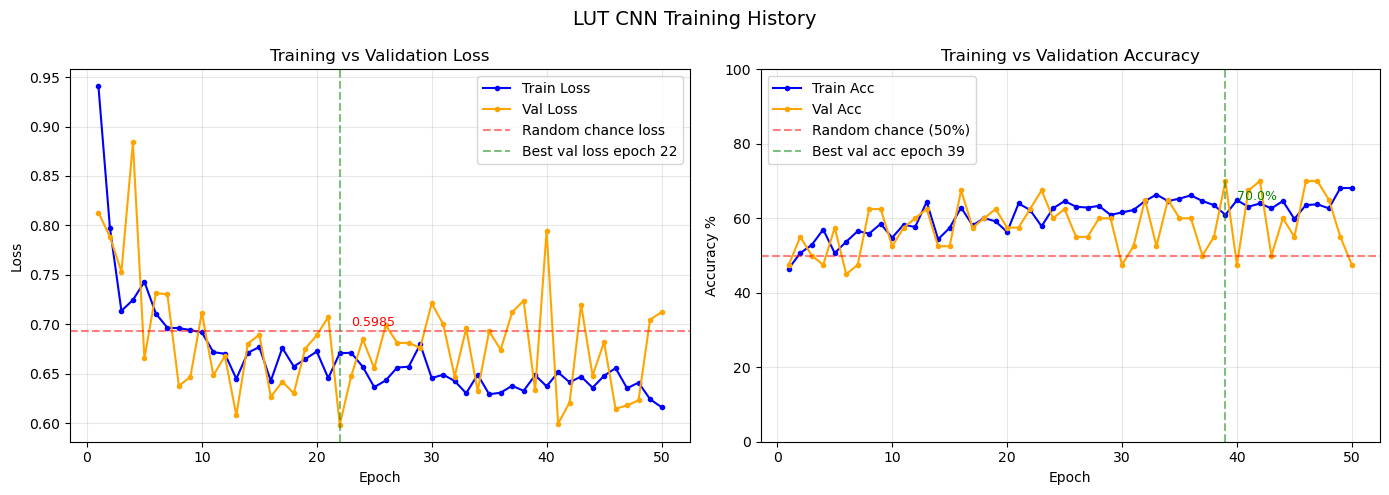


Training Summary:
  Best val acc:  70.0%  at epoch 39
  Best val loss: 0.5985  at epoch 22
  Final train acc:  68.1%
  Final val acc:    47.5%


In [363]:
# Initialize and train
model = LUTFruitCNN(
    num_classes   = 2,
    n_tables      = 8,
    n_comparisons = 4,
    seed          = 42
)

history = train_lut_cnn(model, twoclasstrain_loader, twoclassval_loader, 'best1lutconvlayermodel.pkl', num_epochs=50)

In [444]:
@dataclass
class LUTFruitCNN_Extended:
    """
    Extends a pretrained LUTFruitCNN by adding
    an extra conv layer trained on top of existing features
    
    Architecture:
        [Frozen] LUTConv1 -> ReLU -> Pool
        [Frozen] LUTConv2 -> ReLU -> Pool
        [Frozen] LUTConv3 -> ReLU -> Pool
        [New]    LUTConv4 -> ReLU          <- new trainable layer
        [New]    LUT Classifier            <- new trainable classifier
    """
    num_classes:       int
    
    # Base layer config (must match saved model)
    base_n_tables:      int   = 8
    base_n_comparisons: int   = 4
    
    # New layer config (can be different)
    new_n_tables:       int   = 24
    new_n_comparisons:  int   = 4
    
    seed:               int   = 0
    freeze_conv1:       bool  = True
    
    rng:                np.random.Generator = field(init=False)
    
    # Base layer (loaded from pretrained)
    conv1:              LUTConvLayer  = field(init=False)
    pool1:              LUTPoolLayer  = field(init=False)
    
    # New trainable layer
    conv2:              PartialResidualLUTConvLayer  = field(init=False)
    classifier_ext:     LUTClassifier = field(init=False)
    
    training:           bool          = True
    feature_shape:      tuple         = field(init=False)
    relu1_mask:         np.ndarray    = field(init=False)
    relu2_mask:         np.ndarray    = field(init=False)
    
    def __post_init__(self):
        self.rng   = np.random.default_rng(self.seed)
    
        # Base conv1 uses BASE config
        self.conv1 = LUTConvLayer(
            in_channels   = 3,
            out_channels  = 8,
            kernel_size   = 3,
            n_tables      = self.base_n_tables,       # 8
            n_comparisons = self.base_n_comparisons,  # 4
            rng           = self.rng
        )
        self.pool1 = LUTPoolLayer(2)
        
        # Add new conv layer on top of conv3 output
        # conv3 outputs 16 channels
        self.conv2 = PartialResidualLUTConvLayer(
            in_channels   = 8,   # matches conv3 out_channels
            out_channels  = 16,   # new layer has more channels
            kernel_size   = 3,
            n_tables      = self.new_n_tables,
            n_comparisons = self.new_n_comparisons,
            rng           = self.rng
        )
        self.bn2   = LUTBatchNorm(16)
        self.pool2 = LUTPoolLayer(2)
        
        # New classifier for extended features
        # conv2 outputs 8 channels
        # after pool2 (8x8 spatial)
        # 16 * 8 * 8 = 1024
        cfg_ext = LUTClassifierConfig(
            input_dim     = 1024,
            hidden_dim    = 64,
            num_classes   = self.num_classes,
            n_tables      = self.new_n_tables,
            n_comparisons = self.new_n_comparisons,
            seed          = self.seed
        )
        self.classifier_ext = LUTClassifier(cfg_ext)
        
        print("Extended LUT CNN initialized")
        print(f"  Frozen layers:  conv1, conv2, conv3")
        print(f"  Trainable:      conv4, classifier_ext")
    
    def forward(self, x: np.ndarray) -> np.ndarray:
        """Forward through all layers including new conv4"""
        
        # Frozen conv layers (same as base model)
        x = self.conv1.forward(x)
        self.relu1_mask = (x > 0)
        x = np.maximum(0, x)
        x = self.pool1.forward(x)
        
        x = self.conv2.forward(x)
        self.relu2_mask = (x > 0)
        x = np.maximum(0, x)
        x = self.pool2.forward(x)
        '''
        x = self.conv3.forward(x)
        self.relu3_mask = (x > 0)
        x = np.maximum(0, x)
        x = self.pool3.forward(x)
        '''
        
        # New classifier
        self.feature_shape_ext = x.shape
        logits = self.classifier_ext.forward(x.flatten())
        
        return logits
    
    def backward(self, logits_grad: np.ndarray,
                 learning_rate: float) -> None:
        
        # Backprop through new classifier
        x_flat_grad = self.classifier_ext.backward(
            logits_grad, learning_rate
        )
        x_grad      = x_flat_grad.reshape(self.feature_shape_ext)
        
        # Backprop through new conv2
        x_grad      = self.pool2.backward(x_grad)
        x_grad      = x_grad * self.relu2_mask
        x_grad      = self.conv2.backward(x_grad, learning_rate)
        
        # Stop here if conv1 are frozen
        if self.freeze_conv1:
            return
        
        # Otherwise continue through frozen layers
        
        #x_grad      = self.pool3.backward(x_grad)
        #x_grad      = x_grad * self.relu3_mask
        #x_grad      = self.conv3.backward(x_grad, learning_rate)
        
        #x_grad      = self.pool2.backward(x_grad)
        #x_grad      = x_grad * self.relu2_mask
        #x_grad      = self.conv2.backward(x_grad, learning_rate)
        
        x_grad      = self.pool1.backward(x_grad)
        x_grad      = x_grad * self.relu1_mask
        x_grad      = self.conv1.backward(x_grad, learning_rate)
    
    def save_extended(self, path: str) -> None:
        """Save extended model including new layers"""
        state_dict = get_ext_state_dict(self)
        
        # Add new layer parameters
        state_dict['conv2'] = {
            'S':         self.conv2.lut.S.copy(),
            'anchors_a': self.conv2.lut.anchors_a.copy(),
            'anchors_b': self.conv2.lut.anchors_b.copy(),
        }
        state_dict['classifier_ext'] = {
            'W_proj':     self.classifier_ext.W_proj.copy(),
            'hidden_lut': {
                'S':         self.classifier_ext.hidden_lut.S.copy(),
                'anchors_a': self.classifier_ext.hidden_lut.anchors_a.copy(),
                'anchors_b': self.classifier_ext.hidden_lut.anchors_b.copy(),
            },
            'output_lut': {
                'S':         self.classifier_ext.output_lut.S.copy(),
                'anchors_a': self.classifier_ext.output_lut.anchors_a.copy(),
                'anchors_b': self.classifier_ext.output_lut.anchors_b.copy(),
            },
        }
        state_dict['config']['extended'] = True
        
        os.makedirs(
            os.path.dirname(path) if os.path.dirname(path) else '.',
            exist_ok=True
        )
        
        with open(path, 'wb') as f:
            pickle.dump(state_dict, f)
        
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"Extended model saved to: {path}")
        print(f"File size: {size_mb:.2f} MB")
    
    @classmethod
    def load_extended(cls, path: str) -> 'LUTFruitCNN_Extended':
        """Load extended model from file"""
        with open(path, 'rb') as f:
            state_dict = pickle.load(f)
        
        cfg   = state_dict['config']
        model = cls(
            num_classes   = cfg['num_classes'],
            n_tables      = cfg['n_tables'],
            n_comparisons = cfg['n_comparisons'],
            seed          = cfg['seed']
        )
        
        # Load base layers
        load_ext_state_dict(model, state_dict)
        
        # Load new layers
        if 'conv2' in state_dict:
            model.conv2.lut.S         = state_dict['conv2']['S'].copy()
            model.conv2.lut.anchors_a = state_dict['conv2']['anchors_a'].copy()
            model.conv2.lut.anchors_b = state_dict['conv2']['anchors_b'].copy()
        
        if 'classifier_ext' in state_dict:
            clf = state_dict['classifier_ext']
            model.classifier_ext.W_proj = clf['W_proj'].copy()
            model.classifier_ext.hidden_lut.S = clf['hidden_lut']['S'].copy()
            model.classifier_ext.output_lut.S = clf['output_lut']['S'].copy()
        
        print(f"Extended model loaded from: {path}")
        return model

In [445]:
def get_ext_state_dict(model) -> dict:
    return {
        'config': {
            'num_classes':        model.num_classes,
            'base_n_tables':      model.base_n_tables,
            'base_n_comparisons': model.base_n_comparisons,
            'new_n_tables':       model.new_n_tables,
            'new_n_comparisons':  model.new_n_comparisons,
            'seed':               model.seed,
        },
        'conv1': {
            'S':         model.conv1.lut.S.copy(),
            'anchors_a': model.conv1.lut.anchors_a.copy(),
            'anchors_b': model.conv1.lut.anchors_b.copy(),
        },
        'conv2': {
            'S':         model.conv2.lut.S.copy(),
            'anchors_a': model.conv2.lut.anchors_a.copy(),
            'anchors_b': model.conv2.lut.anchors_b.copy(),
        },
        'classifier_ext': {
            'W_proj':     model.classifier_ext.W_proj.copy(),
            'hidden_lut': {
                'S':         model.classifier_ext.hidden_lut.S.copy(),
                'anchors_a': model.classifier_ext.hidden_lut.anchors_a.copy(),
                'anchors_b': model.classifier_ext.hidden_lut.anchors_b.copy(),
            },
            'output_lut': {
                'S':         model.classifier_ext.output_lut.S.copy(),
                'anchors_a': model.classifier_ext.output_lut.anchors_a.copy(),
                'anchors_b': model.classifier_ext.output_lut.anchors_b.copy(),
            },
        },
        'metadata': {
            'saved_at':    datetime.now().isoformat(),
        }
    }

def save_ext_model(model, path: str,
                   history: dict = None) -> None:
    """Save LUTFruitCNN_Extended to file"""
    os.makedirs(
        os.path.dirname(path) if os.path.dirname(path) else '.',
        exist_ok=True
    )
    
    state_dict = get_ext_state_dict(model)
    
    with open(path, 'wb') as f:
        pickle.dump(state_dict, f)
    
    if history is not None:
        history_path = path.replace('.pkl', '_history.pkl')
        with open(history_path, 'wb') as f:
            pickle.dump(history, f)
    
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"Extended model saved to: {path}  ({size_mb:.2f} MB)")

def load_ext_state_dict(model, state_dict: dict) -> None:
    for layer_name in ['conv1', 'conv2']:
        if layer_name in state_dict:
            layer             = getattr(model, layer_name)
            sd                = state_dict[layer_name]
            layer.lut.S         = sd['S'].copy()
            layer.lut.anchors_a = sd['anchors_a'].copy()
            layer.lut.anchors_b = sd['anchors_b'].copy()
            print(f"  Loaded {layer_name}")
    
    if 'classifier_ext' in state_dict:
        clf_sd = state_dict['classifier_ext']
        model.classifier_ext.W_proj               = clf_sd['W_proj'].copy()
        model.classifier_ext.hidden_lut.S         = clf_sd['hidden_lut']['S'].copy()
        model.classifier_ext.hidden_lut.anchors_a = clf_sd['hidden_lut']['anchors_a'].copy()
        model.classifier_ext.hidden_lut.anchors_b = clf_sd['hidden_lut']['anchors_b'].copy()
        model.classifier_ext.output_lut.S         = clf_sd['output_lut']['S'].copy()
        model.classifier_ext.output_lut.anchors_a = clf_sd['output_lut']['anchors_a'].copy()
        model.classifier_ext.output_lut.anchors_b = clf_sd['output_lut']['anchors_b'].copy()
        print(f"  Loaded classifier_ext")
        
def load_conv1_only(model, base_path: str) -> None:
    """
    Load ONLY conv1 weights from saved base model
    Leave classifier_ext randomly initialized
    
    This is what you actually want when extending:
        conv1     <- pretrained weights  (frozen)
        conv2     <- random init         (trains)
        classifier_ext <- random init    (trains)
    """
    with open(base_path, 'rb') as f:
        base_state = pickle.load(f)
    
    if 'conv1' in base_state:
        model.conv1.lut.S         = base_state['conv1']['S'].copy()
        model.conv1.lut.anchors_a = base_state['conv1']['anchors_a'].copy()
        model.conv1.lut.anchors_b = base_state['conv1']['anchors_b'].copy()
        print(f"  conv1 loaded from {base_path}")
    else:
        print(f"  ⚠️  conv1 not found in {base_path}")
    
    print(f"  conv2 and classifier_ext remain randomly initialized")

  PartialResidualLUTConv: 8 -> 16 channels
    Residual channels: 8 (input + LUT correction)
    New channels:      8 (LUT output only)
LUT Classifier initialized
  Input dim:    1024
  Hidden dim:   64
  Num classes:  2
Extended LUT CNN initialized
  Frozen layers:  conv1, conv2, conv3
  Trainable:      conv4, classifier_ext
  conv1 loaded from best1lutconvlayermodel.pkl
  conv2 and classifier_ext remain randomly initialized
Training extended model with frozen base layers...
training
Epoch [1/50]  LR: 0.00095  Train Loss: 0.7108  Train Acc: 51.5%  Val Loss: 0.6669  Val Acc: 65.0%
Extended model saved to: best2lutconvlayermodel.pkl  (0.75 MB)
  -> Best model saved: val_acc=65.0%  val_loss=0.6669
Epoch [2/50]  LR: 0.00090  Train Loss: 0.7082  Train Acc: 49.6%  Val Loss: 0.7118  Val Acc: 40.0%
Extended model saved to: best2lutconvlayermodel.pkl  (0.75 MB)
  -> Best model saved: val_acc=40.0%  val_loss=0.7118
Epoch [3/50]  LR: 0.00086  Train Loss: 0.6927  Train Acc: 53.1%  Val Loss: 0.698

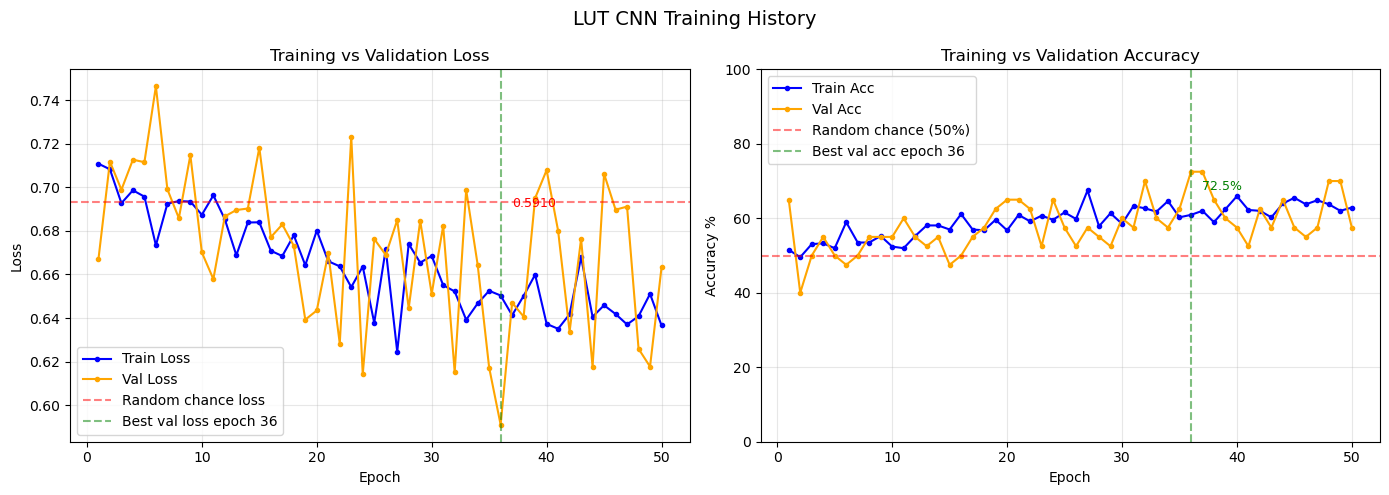


Training Summary:
  Best val acc:  72.5%  at epoch 36
  Best val loss: 0.5910  at epoch 36
  Final train acc:  62.9%
  Final val acc:    57.5%


In [435]:
# ---- Load base model and extend ----
ext_model = LUTFruitCNN_Extended(
    num_classes         = 2,
    base_n_tables       = 8, 
    base_n_comparisons  = 4,   
    new_n_tables        = 24,   
    new_n_comparisons   = 4,   
    seed                = 42
)
# Load pretrained weights into base layers
load_conv1_only(ext_model, 'best1lutconvlayermodel.pkl')

# Freeze base layers, only train conv2 + new classifier
ext_model.freeze_conv1 = True

print("Training extended model with frozen base layers...")
history = train_lut_cnn(ext_model, twoclasstrain_loader, twoclassval_loader, 'best2lutconvlayermodel.pkl', num_epochs=50)

In [310]:
# Later unfreeze conv1 for fine tuning
ext_model.freeze_conv1 = False
history = train_lut_cnn(
    ext_model,
    twoclasstrain_loader,
    twoclassval_loader,
    'best2lutconvlayermodel_finetuned.pkl',
    num_epochs = 50,
)

training
Epoch [1/50]  LR: 0.00095  Train Loss: 0.6566  Train Acc: 61.4%  Val Loss: 0.6834  Val Acc: 62.5%
Extended model saved to: best2lutconvlayermodel_finetuned.pkl  (0.59 MB)
  -> Best model saved: val_acc=62.5%  val_loss=0.6834
Epoch [2/50]  LR: 0.00090  Train Loss: 0.6641  Train Acc: 61.4%  Val Loss: 0.6703  Val Acc: 60.0%
Extended model saved to: best2lutconvlayermodel_finetuned.pkl  (0.59 MB)
  -> Best model saved: val_acc=60.0%  val_loss=0.6703
Epoch [3/50]  LR: 0.00086  Train Loss: 0.6555  Train Acc: 61.1%  Val Loss: 0.6333  Val Acc: 65.0%
Extended model saved to: best2lutconvlayermodel_finetuned.pkl  (0.59 MB)
  -> Best model saved: val_acc=65.0%  val_loss=0.6333
Epoch [4/50]  LR: 0.00081  Train Loss: 0.6712  Train Acc: 57.2%  Val Loss: 0.5877  Val Acc: 67.5%
Extended model saved to: best2lutconvlayermodel_finetuned.pkl  (0.59 MB)
  -> Best model saved: val_acc=67.5%  val_loss=0.5877
Epoch [5/50]  LR: 0.00077  Train Loss: 0.6504  Train Acc: 62.2%  Val Loss: 0.7034  Val Acc:

In [309]:
ext_model.freeze_conv1 = True
train_lut_cnn(
    ext_model,
    twoclasstrain_loader,
    twoclassval_loader,
    'best2lutconvlayermodel_finetuned.pkl',
    num_epochs = 50,
)

training
Epoch [1/50]  LR: 0.00095  Train Loss: 0.6734  Train Acc: 60.0%  Val Loss: 0.6720  Val Acc: 60.0%
Extended model saved to: best2lutconvlayermodel_finetuned.pkl  (0.59 MB)
  -> Best model saved: val_acc=60.0%  val_loss=0.6720
Epoch [2/50]  LR: 0.00090  Train Loss: 0.6761  Train Acc: 58.1%  Val Loss: 0.6818  Val Acc: 60.0%
Epoch [3/50]  LR: 0.00086  Train Loss: 0.6754  Train Acc: 58.3%  Val Loss: 0.6647  Val Acc: 52.5%
Extended model saved to: best2lutconvlayermodel_finetuned.pkl  (0.59 MB)
  -> Best model saved: val_acc=52.5%  val_loss=0.6647
Epoch [4/50]  LR: 0.00081  Train Loss: 0.6855  Train Acc: 57.9%  Val Loss: 0.6772  Val Acc: 67.5%
Epoch [5/50]  LR: 0.00077  Train Loss: 0.6874  Train Acc: 56.8%  Val Loss: 0.6555  Val Acc: 55.0%
Extended model saved to: best2lutconvlayermodel_finetuned.pkl  (0.59 MB)
  -> Best model saved: val_acc=55.0%  val_loss=0.6555
Epoch [6/50]  LR: 0.00074  Train Loss: 0.6568  Train Acc: 61.1%  Val Loss: 0.6441  Val Acc: 62.5%
Extended model saved t

In [341]:
@dataclass
class LUTFruitCNN_3Layer:
    """
    3 LUT conv layer model
    
    Can load pretrained weights from:
        base model  (conv1)
        ext model   (conv1 + conv2)
    And train new conv3 + classifier on top
    
    Architecture:
        Conv1 (3  -> ch1) -> ReLU -> Pool
        Conv2 (ch1-> ch2) -> ReLU -> Pool  
        Conv3 (ch2-> ch3) -> ReLU
        Classifier -> num_classes
    
    Input 32x32:
        After conv1 + pool1: ch1 x 16 x 16
        After conv2 + pool2: ch2 x 8  x 8
        After conv3:         ch3 x 8  x 8
        Flatten:             ch3 * 8 * 8
    """
    num_classes:        int
    
    # Layer 1 config
    base_n_tables:      int   = 8
    base_n_comparisons: int   = 4
    ch1:                int   = 8    # conv1 out channels
    
    # Layer 2 config
    mid_n_tables:       int   = 8
    mid_n_comparisons:  int   = 4
    ch2:                int   = 16   # conv2 out channels
    
    # Layer 3 config
    new_n_tables:       int   = 8
    new_n_comparisons:  int   = 4
    ch3:                int   = 32   # conv3 out channels
    
    seed:               int   = 0
    
    # Freeze flags
    freeze_conv1:       bool  = True
    freeze_conv2:       bool  = True
    
    rng:                np.random.Generator = field(init=False)
    
    # Layers
    conv1:              LUTConvLayer  = field(init=False)
    pool1:              LUTPoolLayer  = field(init=False)
    
    conv2:              LUTConvLayer  = field(init=False)
    pool2:              LUTPoolLayer  = field(init=False)
    
    conv3:              LUTConvLayer  = field(init=False)
    pool3:              LUTPoolLayer  = field(init=False)
    
    classifier:         LUTClassifier = field(init=False)
    
    # Cache
    training:           bool          = True
    feature_shape:      tuple         = field(init=False)
    relu1_mask:         np.ndarray    = field(init=False)
    relu2_mask:         np.ndarray    = field(init=False)
    relu3_mask:         np.ndarray    = field(init=False)

    def __post_init__(self):
        self.rng = np.random.default_rng(self.seed)
        
        # Conv1: 3 -> ch1 channels
        self.conv1 = LUTConvLayer(
            in_channels   = 3,
            out_channels  = self.ch1,
            kernel_size   = 3,
            n_tables      = self.base_n_tables,
            n_comparisons = self.base_n_comparisons,
            rng           = self.rng
        )
        self.pool1 = LUTPoolLayer(2)
        # 32x32 -> 16x16
        
        # Conv2: ch1 -> ch2 channels
        self.conv2 = LUTConvLayer(
            in_channels   = self.ch1,
            out_channels  = self.ch2,
            kernel_size   = 3,
            n_tables      = self.mid_n_tables,
            n_comparisons = self.mid_n_comparisons,
            rng           = self.rng
        )
        self.pool2 = LUTPoolLayer(2)
        # 16x16 -> 8x8
        
        # Conv3: ch2 -> ch3 channels (new trainable layer)
        self.conv3 = LUTConvLayer(
            in_channels   = self.ch2,
            out_channels  = self.ch3,
            kernel_size   = 3,
            n_tables      = self.new_n_tables,
            n_comparisons = self.new_n_comparisons,
            rng           = self.rng
        )
        self.pool3 = LUTPoolLayer(2)
        
        # Classifier
        # input: ch3 * 8 * 8
        clf_input_dim = self.ch3 * 8 * 8
        
        cfg = LUTClassifierConfig(
            input_dim     = clf_input_dim,
            hidden_dim    = 64,
            num_classes   = self.num_classes,
            n_tables      = self.new_n_tables,
            n_comparisons = self.new_n_comparisons,
            seed          = self.seed
        )
        self.classifier = LUTClassifier(cfg)
        
        print(f"LUT CNN 3 Layer initialized")
        print(f"  conv1: {3}->{self.ch1} channels  "
              f"n_tables={self.base_n_tables}  "
              f"n_comparisons={self.base_n_comparisons}  "
              f"{'[frozen]' if self.freeze_conv1 else '[trainable]'}")
        print(f"  conv2: {self.ch1}->{self.ch2} channels  "
              f"n_tables={self.mid_n_tables}  "
              f"n_comparisons={self.mid_n_comparisons}  "
              f"{'[frozen]' if self.freeze_conv2 else '[trainable]'}")
        print(f"  conv3: {self.ch2}->{self.ch3} channels  "
              f"n_tables={self.new_n_tables}  "
              f"n_comparisons={self.new_n_comparisons}  "
              f"[trainable]")
        print(f"  classifier input_dim={clf_input_dim}")

    def forward(self, x: np.ndarray) -> np.ndarray:
        """
        Args:
            x: shape (3, 32, 32)
        Returns:
            logits: shape (num_classes,)
        """
        # Conv1 block
        x               = self.conv1.forward(x)
        self.relu1_mask = (x > 0)
        x               = np.maximum(0, x)
        x               = self.pool1.forward(x)
        # shape: (ch1, 16, 16)
        
        # Conv2 block
        x               = self.conv2.forward(x)
        self.relu2_mask = (x > 0)
        x               = np.maximum(0, x)
        x               = self.pool2.forward(x)
        # shape: (ch2, 8, 8)
        
        # Conv3 block (new)
        x               = self.conv3.forward(x)
        self.relu3_mask = (x > 0)
        x               = np.maximum(0, x)
        #x               = self.pool3.forward(x)
        # shape: (ch3, 4, 4)
        
        self.feature_shape = x.shape
        logits             = self.classifier.forward(x.flatten())
        
        return logits

    def backward(self, logits_grad: np.ndarray,
                 learning_rate: float) -> None:
        
        def rescale(g, target=0.1, eps=1e-8):
            n = np.linalg.norm(g)
            if n > eps:
                return g * (target / n)
            return g
        
        # Classifier backward
        x_flat_grad = self.classifier.backward(logits_grad, learning_rate)
        x_grad      = x_flat_grad.reshape(self.feature_shape)
        
        # Conv3 backward (always trains)
        #x_grad  = self.pool3.backward(x_grad)
        x_grad      = x_grad * self.relu3_mask
        x_grad      = rescale(x_grad)
        x_grad      = self.conv3.backward(x_grad, learning_rate)
        
        # Conv2 backward (only if not frozen)
        if not self.freeze_conv2:
            x_grad  = self.pool2.backward(x_grad)
            x_grad  = x_grad * self.relu2_mask
            x_grad  = rescale(x_grad)
            x_grad  = self.conv2.backward(x_grad, learning_rate)
        else:
            return
        
        # Conv1 backward (only if not frozen)
        if not self.freeze_conv1:
            x_grad  = self.pool1.backward(x_grad)
            x_grad  = x_grad * self.relu1_mask
            x_grad  = rescale(x_grad)
            self.conv1.backward(x_grad, learning_rate)

In [342]:
def get_3layer_state_dict(model) -> dict:
    return {
        'config': {
            'num_classes':        model.num_classes,
            'base_n_tables':      model.base_n_tables,
            'base_n_comparisons': model.base_n_comparisons,
            'ch1':                model.ch1,
            'mid_n_tables':       model.mid_n_tables,
            'mid_n_comparisons':  model.mid_n_comparisons,
            'ch2':                model.ch2,
            'new_n_tables':       model.new_n_tables,
            'new_n_comparisons':  model.new_n_comparisons,
            'ch3':                model.ch3,
            'seed':               model.seed,
        },
        'conv1': {
            'S':         model.conv1.lut.S.copy(),
            'anchors_a': model.conv1.lut.anchors_a.copy(),
            'anchors_b': model.conv1.lut.anchors_b.copy(),
        },
        'conv2': {
            'S':         model.conv2.lut.S.copy(),
            'anchors_a': model.conv2.lut.anchors_a.copy(),
            'anchors_b': model.conv2.lut.anchors_b.copy(),
        },
        'conv3': {
            'S':         model.conv3.lut.S.copy(),
            'anchors_a': model.conv3.lut.anchors_a.copy(),
            'anchors_b': model.conv3.lut.anchors_b.copy(),
        },
        'classifier': {
            'W_proj':     model.classifier.W_proj.copy(),
            'hidden_lut': {
                'S':         model.classifier.hidden_lut.S.copy(),
                'anchors_a': model.classifier.hidden_lut.anchors_a.copy(),
                'anchors_b': model.classifier.hidden_lut.anchors_b.copy(),
            },
            'output_lut': {
                'S':         model.classifier.output_lut.S.copy(),
                'anchors_a': model.classifier.output_lut.anchors_a.copy(),
                'anchors_b': model.classifier.output_lut.anchors_b.copy(),
            },
        },
        'metadata': {
            'saved_at':    datetime.now().isoformat(),
            'input_shape': (3, 32, 32),
        }
    }


def save_3layer_model(model, path: str,
                      history: dict = None) -> None:
    os.makedirs(
        os.path.dirname(path) if os.path.dirname(path) else '.',
        exist_ok=True
    )
    state_dict = get_3layer_state_dict(model)
    with open(path, 'wb') as f:
        pickle.dump(state_dict, f)
    if history is not None:
        history_path = path.replace('.pkl', '_history.pkl')
        with open(history_path, 'wb') as f:
            pickle.dump(history, f)
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"3-layer model saved to: {path}  ({size_mb:.2f} MB)")


def load_3layer_model(path: str) -> LUTFruitCNN_3Layer:
    """Load full 3 layer model from file"""
    with open(path, 'rb') as f:
        state_dict = pickle.load(f)
    
    cfg   = state_dict['config']
    model = LUTFruitCNN_3Layer(
        num_classes         = cfg['num_classes'],
        base_n_tables       = cfg['base_n_tables'],
        base_n_comparisons  = cfg['base_n_comparisons'],
        ch1                 = cfg['ch1'],
        mid_n_tables        = cfg['mid_n_tables'],
        mid_n_comparisons   = cfg['mid_n_comparisons'],
        ch2                 = cfg['ch2'],
        new_n_tables        = cfg['new_n_tables'],
        new_n_comparisons   = cfg['new_n_comparisons'],
        ch3                 = cfg['ch3'],
        seed                = cfg['seed']
    )
    
    for layer_name in ['conv1', 'conv2', 'conv3']:
        layer             = getattr(model, layer_name)
        sd                = state_dict[layer_name]
        layer.lut.S         = sd['S'].copy()
        layer.lut.anchors_a = sd['anchors_a'].copy()
        layer.lut.anchors_b = sd['anchors_b'].copy()
    
    clf_sd = state_dict['classifier']
    model.classifier.W_proj               = clf_sd['W_proj'].copy()
    model.classifier.hidden_lut.S         = clf_sd['hidden_lut']['S'].copy()
    model.classifier.hidden_lut.anchors_a = clf_sd['hidden_lut']['anchors_a'].copy()
    model.classifier.hidden_lut.anchors_b = clf_sd['hidden_lut']['anchors_b'].copy()
    model.classifier.output_lut.S         = clf_sd['output_lut']['S'].copy()
    model.classifier.output_lut.anchors_a = clf_sd['output_lut']['anchors_a'].copy()
    model.classifier.output_lut.anchors_b = clf_sd['output_lut']['anchors_b'].copy()
    
    print(f"3-layer model loaded from: {path}")
    if 'metadata' in state_dict:
        print(f"  Saved at: {state_dict['metadata']['saved_at']}")
    
    return model

LUT Classifier initialized
  Input dim:    2048
  Hidden dim:   64
  Num classes:  2
LUT CNN 3 Layer initialized
  conv1: 3->8 channels  n_tables=8  n_comparisons=4  [frozen]
  conv2: 8->16 channels  n_tables=8  n_comparisons=4  [frozen]
  conv3: 16->32 channels  n_tables=32  n_comparisons=4  [trainable]
  classifier input_dim=2048
Loaded conv1 from saved model
Loaded conv2 from saved model
training
Epoch [1/50]  LR: 0.00095  Train Loss: 1.3044  Train Acc: 51.7%  Val Loss: 0.7597  Val Acc: 57.5%
3-layer model saved to: best3lutconvlayermodel.pkl  (1.41 MB)
  -> Best model saved: val_acc=57.5%  val_loss=0.7597
Epoch [2/50]  LR: 0.00090  Train Loss: 0.8831  Train Acc: 51.7%  Val Loss: 0.6662  Val Acc: 52.5%
3-layer model saved to: best3lutconvlayermodel.pkl  (1.41 MB)
  -> Best model saved: val_acc=52.5%  val_loss=0.6662
Epoch [3/50]  LR: 0.00086  Train Loss: 0.8629  Train Acc: 46.5%  Val Loss: 1.0386  Val Acc: 55.0%
3-layer model saved to: best3lutconvlayermodel.pkl  (1.41 MB)
  -> Best

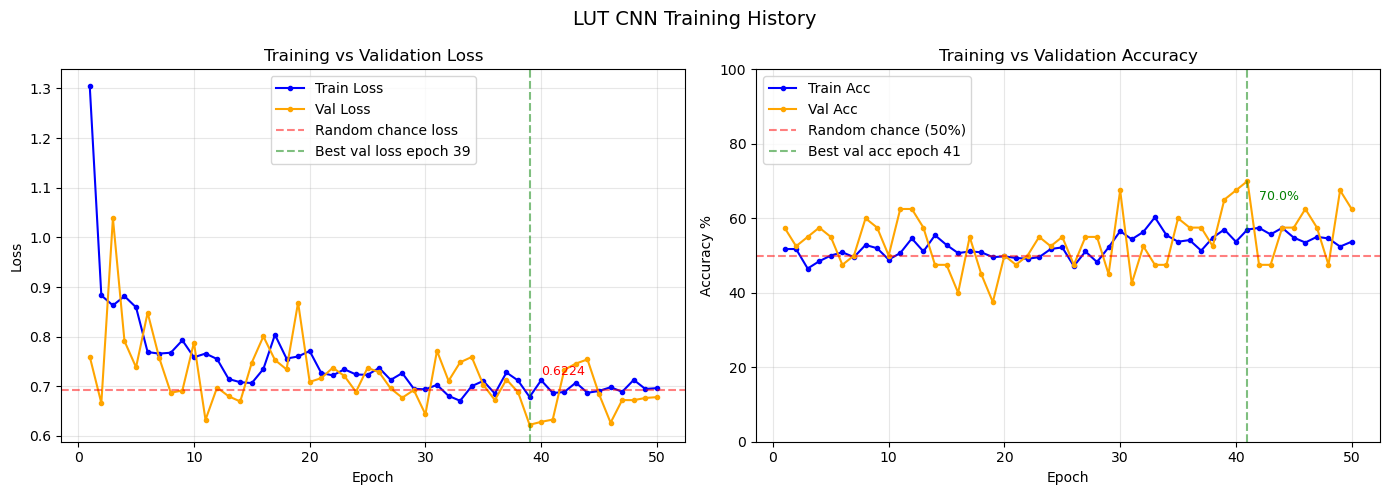


Training Summary:
  Best val acc:  70.0%  at epoch 41
  Best val loss: 0.6224  at epoch 39
  Final train acc:  53.7%
  Final val acc:    62.5%
LUT Classifier initialized
  Input dim:    2048
  Hidden dim:   64
  Num classes:  2
LUT CNN 3 Layer initialized
  conv1: 3->8 channels  n_tables=8  n_comparisons=4  [frozen]
  conv2: 8->16 channels  n_tables=8  n_comparisons=4  [frozen]
  conv3: 16->32 channels  n_tables=32  n_comparisons=4  [trainable]
  classifier input_dim=2048
3-layer model loaded from: best3lutconvlayermodel.pkl
  Saved at: 2026-07-16T11:02:30.848162


In [347]:
# Step 1: Load pretrained 2-layer extended model
ext_state = pickle.load(open('best2lutconvlayermodel_finetuned.pkl', 'rb'))

# Step 2: Create 3-layer model with same base configs
model_3layer = LUTFruitCNN_3Layer(
    num_classes         = 2,
    
    # Match saved conv1 config
    base_n_tables       = 8,
    base_n_comparisons  = 4,
    ch1                 = 8,
    
    # Match saved conv2 config
    mid_n_tables        = 8,
    mid_n_comparisons   = 4,
    ch2                 = 16,
    
    # New conv3 config
    new_n_tables        = 32,
    new_n_comparisons   = 4,
    ch3                 = 32,
    
    seed                = 42,
    freeze_conv1        = True,
    freeze_conv2        = True
)

# Step 3: Load conv1 and conv2 from saved model
for layer_name in ['conv1', 'conv2']:
    if layer_name in ext_state:
        layer             = getattr(model_3layer, layer_name)
        sd                = ext_state[layer_name]
        layer.lut.S         = sd['S'].copy()
        layer.lut.anchors_a = sd['anchors_a'].copy()
        layer.lut.anchors_b = sd['anchors_b'].copy()
        print(f"Loaded {layer_name} from saved model")

# Step 4: Train new conv3 + classifier
history = train_lut_cnn(
    model_3layer,
    twoclasstrain_loader,
    twoclassval_loader,
    'best3lutconvlayermodel.pkl',
    num_epochs = 50
)



LUT Classifier initialized
  Input dim:    2048
  Hidden dim:   64
  Num classes:  2
LUT CNN 3 Layer initialized
  conv1: 3->8 channels  n_tables=8  n_comparisons=4  [frozen]
  conv2: 8->16 channels  n_tables=8  n_comparisons=4  [frozen]
  conv3: 16->32 channels  n_tables=32  n_comparisons=4  [trainable]
  classifier input_dim=2048
3-layer model loaded from: best3lutconvlayermodel.pkl
  Saved at: 2026-07-16T11:13:02.752071
training
Epoch [1/50]  LR: 0.00095  Train Loss: 0.6642  Train Acc: 60.7%  Val Loss: 0.7330  Val Acc: 50.0%
3-layer model saved to: best3lutconvlayermodel.pkl  (1.41 MB)
  -> Best model saved: val_acc=50.0%  val_loss=0.7330
Epoch [2/50]  LR: 0.00090  Train Loss: 0.7237  Train Acc: 53.9%  Val Loss: 0.6518  Val Acc: 62.5%
Epoch [3/50]  LR: 0.00086  Train Loss: 0.7113  Train Acc: 56.3%  Val Loss: 0.6424  Val Acc: 62.5%
Epoch [4/50]  LR: 0.00081  Train Loss: 0.6979  Train Acc: 55.2%  Val Loss: 0.6392  Val Acc: 70.0%
Epoch [5/50]  LR: 0.00077  Train Loss: 0.7198  Train Acc

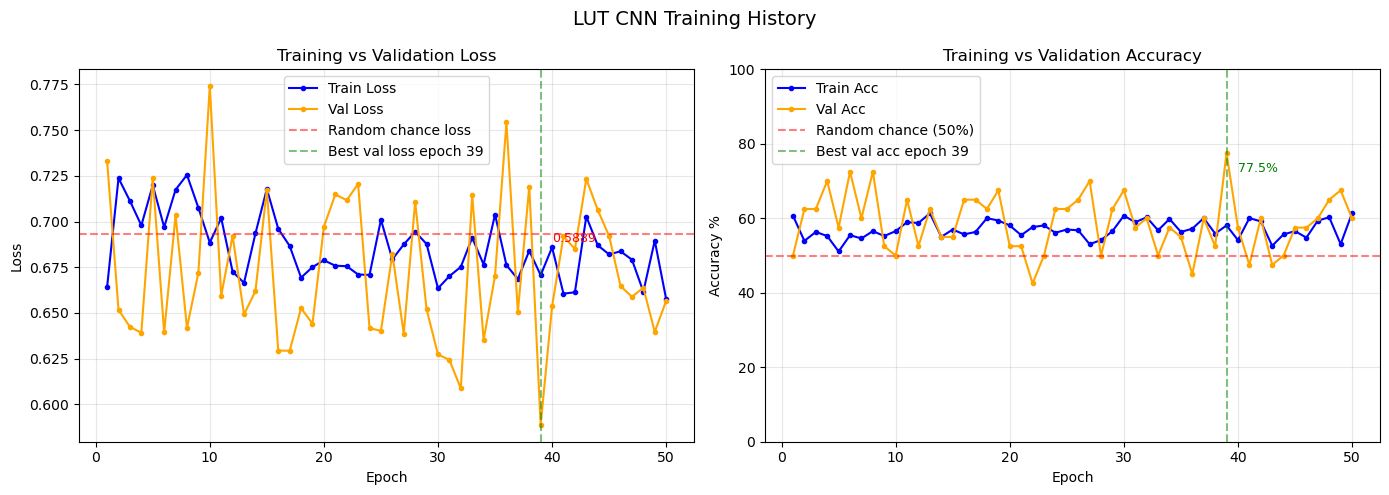


Training Summary:
  Best val acc:  77.5%  at epoch 39
  Best val loss: 0.5889  at epoch 39
  Final train acc:  61.4%
  Final val acc:    60.0%


In [349]:
# Step 5: Later load full 3-layer model
loaded = load_3layer_model('best3lutconvlayermodel.pkl')

loaded.freeze_conv1 = False
loaded.freeze_conv2 = False

history = train_lut_cnn(
    loaded,
    twoclasstrain_loader,
    twoclassval_loader,
    'best3lutconvlayermodel.pkl',
    num_epochs = 50
)

In [219]:
import pickle

# Load and print all keys to see what was actually saved
with open('best1lutconvlayermodel.pkl', 'rb') as f:
    state_dict = pickle.load(f)

# Print top level keys
print("Top level keys:")
for key in state_dict.keys():
    print(f"  {key}")

# Print nested keys
print("\nFull structure:")
def print_dict_structure(d, indent=0):
    for key, value in d.items():
        if isinstance(value, dict):
            print(" " * indent + f"{key}:")
            print_dict_structure(value, indent + 4)
        elif isinstance(value, np.ndarray):
            print(" " * indent + f"{key}: np.ndarray shape={value.shape}")
        else:
            print(" " * indent + f"{key}: {value}")

print_dict_structure(state_dict)

Top level keys:
  config
  conv1
  
        # Conv2 LUT tables and anchors
        'conv2': {
            'S':         model.conv2.lut.S.copy(),
            'anchors_a': model.conv2.lut.anchors_a.copy(),
            'anchors_b': model.conv2.lut.anchors_b.copy(),
        },
        
        # Conv3 LUT tables and anchors
        'conv3': {
            'S':         model.conv3.lut.S.copy(),
            'anchors_a': model.conv3.lut.anchors_a.copy(),
            'anchors_b': model.conv3.lut.anchors_b.copy(),
        },
        classifier
  metadata

Full structure:
config:
    num_classes: 2
    n_tables: 8
    n_comparisons: 4
    seed: 42
conv1:
    S: np.ndarray shape=(8, 16, 8)
    anchors_a: np.ndarray shape=(8, 4)
    anchors_b: np.ndarray shape=(8, 4)

        # Conv2 LUT tables and anchors
        'conv2': {
            'S':         model.conv2.lut.S.copy(),
            'anchors_a': model.conv2.lut.anchors_a.copy(),
            'anchors_b': model.conv2.lut.anchors_b.copy(),
       

In [169]:
model = LUTFruitCNN(
    num_classes   = 2,
    n_tables      = 64,
    n_comparisons = 8,
    seed          = 42
)

def check_gradients(model, train_loader):
    """
    Check gradient magnitudes at each layer
    to confirm signal is flowing
    """
    images, labels = next(iter(train_loader))
    img_tensor     = images[0]
    label          = labels[0]
    
    x      = preprocess_for_lut(img_tensor)
    target = label.item()
    
    # Forward
    logits         = model.forward(x)
    loss, logit_grad = cross_entropy_from_logits(logits, target)
    
    print(f"Loss:              {loss:.4f}")
    print(f"Logit grad norm:   {np.linalg.norm(logit_grad):.6f}")
    
    # Classifier backward
    x_flat_grad    = model.classifier.backward(logit_grad, learning_rate=0.01)
    print(f"After classifier:  {np.linalg.norm(x_flat_grad):.6f}")
    
    x_grad         = x_flat_grad.reshape(model.feature_shape)
    
    # Block 3
    x_grad         = model.pool3.backward(x_grad)
    x_grad         = x_grad * model.relu3_mask
    print(f"After relu3 mask:  {np.linalg.norm(x_grad):.6f}")
    #x_grad         = model.bn3.backward(x_grad, 0.01)
    #print(f"After bn3:         {np.linalg.norm(x_grad):.6f}")
    x_grad         = model.conv3.backward(x_grad, 0.01)
    print(f"After conv3:       {np.linalg.norm(x_grad):.6f}")
    
    # Block 2
    x_grad         = model.pool2.backward(x_grad)
    x_grad         = x_grad * model.relu2_mask
    print(f"After relu2 mask:  {np.linalg.norm(x_grad):.6f}")
    #x_grad         = model.bn2.backward(x_grad, 0.01)
    #print(f"After bn2:         {np.linalg.norm(x_grad):.6f}")
    x_grad         = model.conv2.backward(x_grad, 0.01)
    print(f"After conv2:       {np.linalg.norm(x_grad):.6f}")
    
    # Block 1
    x_grad         = model.pool1.backward(x_grad)
    x_grad         = x_grad * model.relu1_mask
    print(f"After relu1 mask:  {np.linalg.norm(x_grad):.6f}")
    #x_grad         = model.bn1.backward(x_grad, 0.01)
    #print(f"After bn1:         {np.linalg.norm(x_grad):.6f}")
    x_grad         = model.conv1.backward(x_grad, 0.01)
    print(f"After conv1:       {np.linalg.norm(x_grad):.6f}")

check_gradients(model, twoclasstrain_loader)

def check_table_updates(model, train_loader):
    """
    Confirm LUT tables actually change after one backward
    """
    images, labels = next(iter(train_loader))
    x      = preprocess_for_lut(images[0])
    target = labels[0].item()
    
    # Snapshot S tables before
    S_conv1_before = model.conv1.lut.S.copy()
    S_clf_before   = model.classifier.output_lut.S.copy()
    
    # One forward + backward
    logits         = model.forward(x)
    loss, grad     = cross_entropy_from_logits(logits, target)
    model.backward(grad, learning_rate=0.01)
    
    # Check if tables changed
    conv1_change = np.abs(model.conv1.lut.S - S_conv1_before).max()
    clf_change   = np.abs(model.classifier.output_lut.S - S_clf_before).max()
    
    print(f"Conv1 LUT max change:      {conv1_change:.8f}")
    print(f"Classifier LUT max change: {clf_change:.8f}")
    
    # If conv1_change is 0.0 -> conv1 backward not updating tables
    # If clf_change is 0.0   -> classifier backward not updating tables

check_table_updates(model, twoclasstrain_loader)

LUT Classifier initialized
  Input dim:    256
  Hidden dim:   32
  Num classes:  2
LUT CNN initialized
  n_tables:      64
  n_comparisons: 8
Loss:              9.3949
Logit grad norm:   1.414096
After classifier:  0.273007
After relu3 mask:  0.266491
After conv3:       0.213380
After relu2 mask:  0.202545
After conv2:       0.173102
After relu1 mask:  0.141714
After conv1:       0.144690
Conv1 LUT max change:      0.00015270
Classifier LUT max change: 0.01188899


In [170]:
def debug_first_batches(model, train_loader, n_batches=30):
    """
    Watch loss on very first batches
    tells us if model is learning at all
    """
    losses   = []
    accs     = []
    preds    = []
    lr       = 0.0001   # start with small lr
    
    for step, (images, labels) in enumerate(train_loader):
        if step >= n_batches:
            break
        
        for img_tensor, label in zip(images, labels):
            x      = preprocess_for_lut(img_tensor)
            target = label.item()
            
            logits = model.forward(x)
            loss, grad = cross_entropy_from_logits(logits, target)
            losses.append(loss)
            accs.append(int(np.argmax(logits) == target))
            preds.append(int(np.argmax(logits)))
            
            model.backward(grad, lr)
    
    print("Step  Loss    Acc")
    for i, (l, a, p) in enumerate(zip(losses, accs, preds)):
        print(f"  {i+1:2d}   {l:.4f}  {a}  {p}")
    
    print(f"\nLoss trend:  {np.average(losses[0:50]):.4f} -> {np.average(losses[-51:-1]):.4f}")
    print(f"Should decrease if learning")

debug_first_batches(model, twoclasstrain_loader)

Step  Loss    Acc
   1   0.1140  1  1
   2   0.0303  1  1
   3   3.6894  0  0
   4   0.5229  1  1
   5   4.5442  0  1
   6   0.0012  1  1
   7   2.4211  0  0
   8   12.7067  0  1
   9   0.1452  1  0
  10   8.0448  0  0
  11   0.0189  1  0
  12   19.0678  0  1
  13   0.3030  1  1
  14   2.8287  0  1
  15   0.0000  1  1
  16   3.3312  0  1
  17   2.8260  0  1
  18   0.0887  1  0
  19   0.0045  1  0
  20   0.4453  1  0
  21   8.8002  0  1
  22   0.0488  1  0
  23   0.2617  1  1
  24   7.2738  0  0
  25   0.2400  1  1
  26   4.1654  0  1
  27   0.0678  1  0
  28   0.0046  1  1
  29   0.0000  1  0
  30   0.0001  1  1
  31   0.0002  1  1
  32   0.0046  1  0
  33   0.0000  1  1
  34   4.1004  0  1
  35   3.2178  0  1
  36   0.0051  1  0
  37   0.6220  1  0
  38   0.0014  1  0
  39   0.0008  1  0
  40   0.0000  1  1
  41   0.4778  1  1
  42   8.1556  0  1
  43   0.0013  1  1
  44   1.9430  0  1
  45   1.8280  0  0
  46   0.0443  1  0
  47   4.3936  0  0
  48   1.0553  0  0
  49   1.0109  0  1


In [186]:
def check_logit_distribution(model, train_loader, n_samples=20):
    """
    If logits are always near zero
    softmax outputs uniform distribution
    model cant distinguish classes
    """
    for images, labels in train_loader:
        for img_tensor, label in zip(images[:n_samples], labels[:n_samples]):
            x      = preprocess_for_lut(img_tensor)
            logits = model.forward(x)
            probs  = softmax(logits)
            
            print(f"Logits: {logits.round(3)}")
            print(f"Probs:  {probs.round(3)}")
            print(f"Pred:   {np.argmax(logits)}  True: {label.item()}")
            print()
        break

check_logit_distribution(model, twoclasstrain_loader)

# Bad output (uniform, not learning):
# Logits: [0.001 0.002 -0.001 0.001 -0.002 0.001]
# Probs:  [0.167 0.167  0.167 0.167  0.167 0.167]

# Good output (learning):
# Logits: [2.1  -0.3   0.1  -0.5  -1.2   0.4]
# Probs:  [0.72  0.07  0.10  0.05  0.03  0.13]

Logits: [ 0.795 -1.208]
Probs:  [0.881 0.119]
Pred:   0  True: 1

Logits: [0.127 1.026]
Probs:  [0.289 0.711]
Pred:   1  True: 0

Logits: [-1.756  1.49 ]
Probs:  [0.037 0.963]
Pred:   1  True: 1

Logits: [-1.285  0.541]
Probs:  [0.139 0.861]
Pred:   1  True: 1

Logits: [-1.475 -1.237]
Probs:  [0.441 0.559]
Pred:   1  True: 1

Logits: [ 3.362 -1.868]
Probs:  [0.995 0.005]
Pred:   0  True: 0

Logits: [-1.247 -0.891]
Probs:  [0.412 0.588]
Pred:   1  True: 0

Logits: [1.933 3.105]
Probs:  [0.236 0.764]
Pred:   1  True: 0

Logits: [ 2.941 -1.565]
Probs:  [0.989 0.011]
Pred:   0  True: 0

Logits: [-2.967 -2.975]
Probs:  [0.502 0.498]
Pred:   0  True: 0

Logits: [-2.083  1.412]
Probs:  [0.029 0.971]
Pred:   1  True: 1

Logits: [-8.068 -2.965]
Probs:  [0.006 0.994]
Pred:   1  True: 1

Logits: [-4.527 -3.714]
Probs:  [0.307 0.693]
Pred:   1  True: 1

Logits: [-2.753 -5.297]
Probs:  [0.927 0.073]
Pred:   0  True: 0

Logits: [ 1.087 -1.469]
Probs:  [0.928 0.072]
Pred:   0  True: 1

Logits: [-2.59

In [128]:
def overfit_one_image(model, train_loader, n_steps=400):
    """
    Try to perfectly memorize ONE image
    If model cant do this -> fundamental learning bug
    If model can do this  -> needs more data/epochs
    """
    # Get one image
    images, labels = next(iter(train_loader))
    x      = preprocess_for_lut(images[0])
    target = labels[0].item()
    
    print(f"Trying to memorize class {target}")
    print(f"Step  Loss    Pred  Correct")
    
    lr     = 0.001
    
    for step in range(1, n_steps + 1):
        logits     = model.forward(x)
        loss, grad = cross_entropy_from_logits(logits, target)
        pred       = np.argmax(logits)
        correct    = pred == target
        
        if step % 20 == 0:
            print(f"  {step:3d}  {loss:.4f}   {pred}     {correct}")
        
        model.backward(grad, lr)
    
    print(f"\nFinal loss: {loss:.4f}")
    print(f"Random loss: {0.69:.4f}")
    
    if loss < 0.5:
        print("Model CAN memorize -> learning works")
        print("Problem is generalization not learning itself")
    elif loss < 1.79:
        print("Model partially learning but slowly")
        print("Try higher lr or more steps")
    else:
        print("Model CANNOT memorize single image")
        print("Fundamental learning bug still exists")

overfit_one_image(model, twoclasstrain_loader)

Trying to memorize class 0
Step  Loss    Pred  Correct
   20  0.0063   0     True
   40  0.0025   0     True
   60  0.0564   0     True
   80  0.0001   0     True
  100  0.0001   0     True
  120  0.0001   0     True
  140  0.0001   0     True
  160  0.0001   0     True
  180  0.0001   0     True
  200  0.0001   0     True
  220  0.0001   0     True
  240  0.0001   0     True
  260  0.0001   0     True
  280  0.0001   0     True
  300  0.0001   0     True
  320  0.0001   0     True
  340  0.0001   0     True
  360  0.0001   0     True
  380  0.0001   0     True
  400  0.0001   0     True

Final loss: 0.0001
Random loss: 0.6900
✅ Model CAN memorize -> learning works
   Problem is generalization not learning itself


In [173]:
def overfit_two_images(model, train_loader):
    """
    Try to memorize exactly two images
    one from each class
    
    If model can do this -> learning works
    just needs better data/balance
    """
    # Get one image from each class
    class_images = {}
    for images, labels in train_loader:
        for img, label in zip(images, labels):
            t = label.item()
            if t not in class_images:
                class_images[t] = preprocess_for_lut(img)
            if len(class_images) == 2:
                break
        if len(class_images) == 2:
            break
    
    x0, x1   = class_images[0], class_images[1]
    lr       = 0.005
    
    print("Step  Loss0  Loss1  Pred0  Pred1")
    
    for step in range(1, 201):
        # Train on both
        l0, g0 = cross_entropy_from_logits(model.forward(x0), 0)
        model.backward(g0, lr)
        
        l1, g1 = cross_entropy_from_logits(model.forward(x1), 1)
        model.backward(g1, lr)
        
        if step % 20 == 0:
            p0 = np.argmax(model.forward(x0))
            p1 = np.argmax(model.forward(x1))
            print(f"  {step:3d}   {l0:.3f}  {l1:.3f}    {p0}      {p1}")
    
    print(f"\nIf Pred0=0 and Pred1=1 -> model can distinguish classes")
    print(f"If both predict same class -> class bias problem")

overfit_two_images(model, twoclasstrain_loader)

Step  Loss0  Loss1  Pred0  Pred1
   20   0.000  0.001    0      1
   40   0.000  0.001    0      1
   60   0.000  0.001    0      1
   80   0.000  0.001    0      1
  100   0.000  0.001    0      1
  120   0.019  0.000    0      1
  140   0.022  0.014    0      1
  160   8.673  0.066    0      1
  180   0.000  0.000    0      1
  200   0.000  0.001    0      1

If Pred0=0 and Pred1=1 -> model can distinguish classes
If both predict same class -> class bias problem


In [187]:
def check_table_collisions(model, train_loader, n_images=10):
    """
    Check how many different patches map to same table row
    High collision = contradictory updates = poor learning
    """
    row_hits = np.zeros((
        model.conv1.lut.n_tables,
        1 << model.conv1.lut.n_comparisons
    ))
    
    model.training = False
    count = 0
    
    for images, labels in train_loader:
        for img_tensor, label in zip(images, labels):
            if count >= n_images:
                break
            
            x = preprocess_for_lut(img_tensor)
            model.forward(x)
            
            # Count how many patches hit each row
            for p in range(len(model.conv1.all_caches)):
                cache = model.conv1.all_caches[p]
                for t in range(model.conv1.lut.n_tables):
                    row_hits[t, cache.j[t]] += 1
            
            count += 1
        if count >= n_images:
            break
    
    print(f"Conv1 table row collision stats ({n_images} images):")
    print(f"  Total patches processed: {count * 1024}")
    print(f"  Rows per table:          {1 << model.conv1.lut.n_comparisons}")
    print(f"  Avg hits per row:        {row_hits.mean():.1f}")
    print(f"  Max hits per row:        {row_hits.max():.0f}")
    print(f"  Rows never hit:          {(row_hits == 0).sum()}")
    print(f"  Rows hit > 100 times:    {(row_hits > 100).sum()}")

check_table_collisions(model, twoclasstrain_loader)

Conv1 table row collision stats (10 images):
  Total patches processed: 10240
  Rows per table:          64
  Avg hits per row:        160.0
  Max hits per row:        4059
  Rows never hit:          307
  Rows hit > 100 times:    549


In [182]:
def monitor_class_tables(model, train_loader, n_images=20):
    """
    Check if class 0 and class 1 images
    hit different table rows
    
    If they hit the same rows -> model cant distinguish them
    If they hit different rows -> model can learn separation
    """
    class_row_hits = {0: np.zeros((
                            model.conv3.lut.n_tables,
                            1 << model.conv3.lut.n_comparisons
                        )),
                      1: np.zeros((
                            model.conv3.lut.n_tables,
                            1 << model.conv3.lut.n_comparisons
                        ))}
    
    model.training = False
    count          = 0
    
    for images, labels in train_loader:
        for img_tensor, label in zip(images, labels):
            if count >= n_images:
                break
            
            x      = preprocess_for_lut(img_tensor)
            target = label.item()
            model.forward(x)
            
            # Check which rows conv3 hits for each class
            for p in range(len(model.conv3.all_caches)):
                cache = model.conv3.all_caches[p]
                for t in range(model.conv3.lut.n_tables):
                    class_row_hits[target][t, cache.j[t]] += 1
            
            count += 1
        if count >= n_images:
            break
    
    # Check overlap between class 0 and class 1 row hits
    overlap = np.logical_and(
        class_row_hits[0] > 0,
        class_row_hits[1] > 0
    ).sum()
    
    total_rows = (
        model.conv3.lut.n_tables *
        (1 << model.conv3.lut.n_comparisons)
    )
    
    print(f"\nConv3 table analysis:")
    print(f"  Total rows:              {total_rows}")
    print(f"  Rows hit by class 0:     {(class_row_hits[0] > 0).sum()}")
    print(f"  Rows hit by class 1:     {(class_row_hits[1] > 0).sum()}")
    print(f"  Rows shared by both:     {overlap}")
    print(f"  Overlap ratio:           {overlap/total_rows:.2%}")
    
    if overlap / total_rows > 0.8:
        print("High overlap - classes hard to distinguish")
    elif overlap / total_rows > 0.5:
        print("Medium overlap - partial separation")
    else:
        print("Low overlap - good class separation")

monitor_class_tables(model, twoclasstrain_loader)


Conv3 table analysis:
  Total rows:              2048
  Rows hit by class 0:     2025
  Rows hit by class 1:     2045
  Rows shared by both:     2022
  Overlap ratio:           98.73%
High overlap - classes hard to distinguish


In [313]:
#Similar CNN comparison
class CompToLUTfruitClassificationCNN(nn.Module):
    def __init__(self, num_classes=6): 
        super(CompToLUTfruitClassificationCNN, self).__init__()
        
        self.features = nn.Sequential(
            #Block 1
            nn.Conv2d(3, 32, kernel_size=5, padding=2),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            #Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            #Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
        )
        
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((2, 2)),
            nn.Flatten(),
            nn.Linear(256*2*2, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),    
            nn.Linear(64, 32),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),       
            nn.Linear(32, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [168]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

model = CompToLUTfruitClassificationCNN(num_classes=6).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
num_epochs = 300

# Track losses
train_losses = []
val_losses   = []
train_accs   = []
val_accs     = []

best_val_loss = float('inf')

for epoch in range(num_epochs):
    model.train()
    running_train_loss = 0.0
    correct_train      = 0
    total_train        = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        # Track loss and accuracy
        running_train_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total_train  += labels.size(0)
        correct_train += (predicted == labels).sum().item()
    
    avg_train_loss = running_train_loss / len(train_loader)
    train_acc      = 100 * correct_train / total_train
        
    model.eval()  # set model to evaluation mode
    running_val_loss = 0.0
    correct_val      = 0
    total_val        = 0
    
    with torch.no_grad():  # no gradients needed for validation
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            
            outputs  = model(images)
            loss     = criterion(outputs, labels)
            
            # Track loss and accuracy
            running_val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total_val    += labels.size(0)
            correct_val  += (predicted == labels).sum().item()
    
    avg_val_loss = running_val_loss / len(val_loader)
    val_acc      = 100 * correct_val / total_val
    
    # Save losses
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)
    
    # Print progress
    print(f"Epoch [{epoch+1}/{num_epochs}]  "
          f"Train Loss: {avg_train_loss:.4f}  Train Acc: {train_acc:.2f}%  "
          f"Val Loss: {avg_val_loss:.4f}  Val Acc: {val_acc:.2f}%")
    
    # Save model if validation loss improved
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), 'compCNN_best_model.pth')
        print(f"  -> Model saved with val loss: {best_val_loss:.4f}")

Using device: mps
Epoch [1/300]  Train Loss: 1.7832  Train Acc: 21.40%  Val Loss: 1.7210  Val Acc: 25.83%
  -> Model saved with val loss: 1.7210
Epoch [2/300]  Train Loss: 1.7556  Train Acc: 21.62%  Val Loss: 1.6649  Val Acc: 35.83%
  -> Model saved with val loss: 1.6649
Epoch [3/300]  Train Loss: 1.7297  Train Acc: 25.11%  Val Loss: 1.6571  Val Acc: 20.83%
  -> Model saved with val loss: 1.6571
Epoch [4/300]  Train Loss: 1.7047  Train Acc: 25.33%  Val Loss: 1.6940  Val Acc: 25.00%
Epoch [5/300]  Train Loss: 1.6885  Train Acc: 26.93%  Val Loss: 1.6380  Val Acc: 30.83%
  -> Model saved with val loss: 1.6380
Epoch [6/300]  Train Loss: 1.6539  Train Acc: 28.97%  Val Loss: 1.5712  Val Acc: 35.83%
  -> Model saved with val loss: 1.5712
Epoch [7/300]  Train Loss: 1.6459  Train Acc: 27.37%  Val Loss: 1.6305  Val Acc: 31.67%
Epoch [8/300]  Train Loss: 1.6168  Train Acc: 28.68%  Val Loss: 1.5786  Val Acc: 27.50%
Epoch [9/300]  Train Loss: 1.6071  Train Acc: 28.89%  Val Loss: 1.5355  Val Acc: 27

Epoch [81/300]  Train Loss: 1.1471  Train Acc: 53.64%  Val Loss: 0.9870  Val Acc: 66.67%
Epoch [82/300]  Train Loss: 1.1358  Train Acc: 55.60%  Val Loss: 1.1706  Val Acc: 55.83%
Epoch [83/300]  Train Loss: 1.1655  Train Acc: 53.42%  Val Loss: 0.9874  Val Acc: 65.83%
Epoch [84/300]  Train Loss: 1.1529  Train Acc: 54.88%  Val Loss: 1.0100  Val Acc: 63.33%
Epoch [85/300]  Train Loss: 1.1499  Train Acc: 55.31%  Val Loss: 1.3104  Val Acc: 50.83%
Epoch [86/300]  Train Loss: 1.1239  Train Acc: 56.04%  Val Loss: 1.0088  Val Acc: 61.67%
Epoch [87/300]  Train Loss: 1.1060  Train Acc: 57.86%  Val Loss: 0.9274  Val Acc: 61.67%
  -> Model saved with val loss: 0.9274
Epoch [88/300]  Train Loss: 1.1176  Train Acc: 56.84%  Val Loss: 0.9391  Val Acc: 65.83%
Epoch [89/300]  Train Loss: 1.1051  Train Acc: 56.99%  Val Loss: 1.0039  Val Acc: 67.50%
Epoch [90/300]  Train Loss: 1.1253  Train Acc: 56.62%  Val Loss: 1.0043  Val Acc: 58.33%
Epoch [91/300]  Train Loss: 1.0987  Train Acc: 58.37%  Val Loss: 0.9314

Epoch [167/300]  Train Loss: 0.7632  Train Acc: 73.87%  Val Loss: 0.7675  Val Acc: 73.33%
Epoch [168/300]  Train Loss: 0.7280  Train Acc: 74.31%  Val Loss: 0.6291  Val Acc: 75.83%
Epoch [169/300]  Train Loss: 0.7056  Train Acc: 74.96%  Val Loss: 0.7734  Val Acc: 70.00%
Epoch [170/300]  Train Loss: 0.6946  Train Acc: 75.69%  Val Loss: 0.6267  Val Acc: 80.00%
Epoch [171/300]  Train Loss: 0.7436  Train Acc: 73.14%  Val Loss: 0.5720  Val Acc: 81.67%
  -> Model saved with val loss: 0.5720
Epoch [172/300]  Train Loss: 0.7045  Train Acc: 75.04%  Val Loss: 0.5627  Val Acc: 79.17%
  -> Model saved with val loss: 0.5627
Epoch [173/300]  Train Loss: 0.7541  Train Acc: 73.51%  Val Loss: 1.0415  Val Acc: 70.00%
Epoch [174/300]  Train Loss: 0.7667  Train Acc: 72.20%  Val Loss: 0.6212  Val Acc: 83.33%
Epoch [175/300]  Train Loss: 0.7262  Train Acc: 73.14%  Val Loss: 0.6387  Val Acc: 77.50%
Epoch [176/300]  Train Loss: 0.7501  Train Acc: 73.00%  Val Loss: 0.8357  Val Acc: 69.17%
Epoch [177/300]  Train

Epoch [257/300]  Train Loss: 0.5067  Train Acc: 82.82%  Val Loss: 0.6172  Val Acc: 80.00%
Epoch [258/300]  Train Loss: 0.5252  Train Acc: 82.24%  Val Loss: 0.5094  Val Acc: 84.17%
Epoch [259/300]  Train Loss: 0.5211  Train Acc: 82.68%  Val Loss: 0.6884  Val Acc: 80.00%
Epoch [260/300]  Train Loss: 0.5889  Train Acc: 80.71%  Val Loss: 0.5711  Val Acc: 81.67%
Epoch [261/300]  Train Loss: 0.4863  Train Acc: 83.26%  Val Loss: 0.6541  Val Acc: 75.83%
Epoch [262/300]  Train Loss: 0.5168  Train Acc: 81.88%  Val Loss: 0.5110  Val Acc: 83.33%
Epoch [263/300]  Train Loss: 0.4565  Train Acc: 85.15%  Val Loss: 0.5672  Val Acc: 84.17%
Epoch [264/300]  Train Loss: 0.4776  Train Acc: 84.57%  Val Loss: 0.5087  Val Acc: 82.50%
Epoch [265/300]  Train Loss: 0.5496  Train Acc: 81.66%  Val Loss: 0.7992  Val Acc: 75.00%
Epoch [266/300]  Train Loss: 0.4993  Train Acc: 83.92%  Val Loss: 0.6851  Val Acc: 82.50%
Epoch [267/300]  Train Loss: 0.4903  Train Acc: 84.06%  Val Loss: 0.5089  Val Acc: 85.00%
Epoch [268

In [448]:
#Test pure classifier for performance comparison
class PureLinearFruitClassificationCNN(nn.Module):
    def __init__(self, num_classes=2): 
        super(PureLinearFruitClassificationCNN, self).__init__()
            
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, num_classes),
        )

    def forward(self, x):
        x = self.classifier(x)
        return x

In [449]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

model = PureLinearFruitClassificationCNN(num_classes=2).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
num_epochs = 50

# Track losses
train_losses = []
val_losses   = []
train_accs   = []
val_accs     = []

best_val_loss = float('inf')

for epoch in range(num_epochs):
    model.train()
    running_train_loss = 0.0
    correct_train      = 0
    total_train        = 0
    for images, labels in twoclasstrain_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        # Track loss and accuracy
        running_train_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total_train  += labels.size(0)
        correct_train += (predicted == labels).sum().item()
    
    avg_train_loss = running_train_loss / len(train_loader)
    train_acc      = 100 * correct_train / total_train
        
    model.eval()  # set model to evaluation mode
    running_val_loss = 0.0
    correct_val      = 0
    total_val        = 0
    
    with torch.no_grad():  # no gradients needed for validation
        for images, labels in twoclassval_loader:
            images, labels = images.to(device), labels.to(device)
            
            outputs  = model(images)
            loss     = criterion(outputs, labels)
            
            # Track loss and accuracy
            running_val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total_val    += labels.size(0)
            correct_val  += (predicted == labels).sum().item()
    
    avg_val_loss = running_val_loss / len(val_loader)
    val_acc      = 100 * correct_val / total_val
    
    # Save losses
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)
    
    # Print progress
    print(f"Epoch [{epoch+1}/{num_epochs}]  "
          f"Train Loss: {avg_train_loss:.4f}  Train Acc: {train_acc:.2f}%  "
          f"Val Loss: {avg_val_loss:.4f}  Val Acc: {val_acc:.2f}%")
    
    # Save model if validation loss improved
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), 'PureLinearCompCNN_best_model.pth')
        print(f"  -> Model saved with val loss: {best_val_loss:.4f}")

Using device: mps
Epoch [1/50]  Train Loss: 0.3322  Train Acc: 51.09%  Val Loss: 0.5184  Val Acc: 55.00%
  -> Model saved with val loss: 0.5184
Epoch [2/50]  Train Loss: 0.2977  Train Acc: 56.33%  Val Loss: 0.4584  Val Acc: 42.50%
  -> Model saved with val loss: 0.4584
Epoch [3/50]  Train Loss: 0.3144  Train Acc: 53.93%  Val Loss: 0.3859  Val Acc: 52.50%
  -> Model saved with val loss: 0.3859
Epoch [4/50]  Train Loss: 0.2951  Train Acc: 54.59%  Val Loss: 0.4199  Val Acc: 47.50%
Epoch [5/50]  Train Loss: 0.2906  Train Acc: 58.95%  Val Loss: 0.3813  Val Acc: 50.00%
  -> Model saved with val loss: 0.3813
Epoch [6/50]  Train Loss: 0.4196  Train Acc: 53.28%  Val Loss: 0.6305  Val Acc: 57.50%
Epoch [7/50]  Train Loss: 0.2780  Train Acc: 58.08%  Val Loss: 0.5828  Val Acc: 52.50%
Epoch [8/50]  Train Loss: 0.2668  Train Acc: 61.57%  Val Loss: 0.4461  Val Acc: 50.00%
Epoch [9/50]  Train Loss: 0.3245  Train Acc: 51.75%  Val Loss: 0.5339  Val Acc: 50.00%
Epoch [10/50]  Train Loss: 0.3283  Train Ac

In [317]:
#Test one normal conv layer CNN for performance comparison with one layer lut conv
class OneConvLayerFruitClassificationCNN(nn.Module):
    def __init__(self, num_classes=2): 
        super(OneConvLayerFruitClassificationCNN, self).__init__()
        
        self.features = nn.Sequential(
            #Block 1
            nn.Conv2d(3, 8, kernel_size=3, padding=1),
            nn.BatchNorm2d(8),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )
            
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(2048, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),    
            nn.Linear(64, 32),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),       
            nn.Linear(32, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [318]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

model = OneConvLayerFruitClassificationCNN(num_classes=2).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
num_epochs = 50

# Track losses
train_losses = []
val_losses   = []
train_accs   = []
val_accs     = []

best_val_loss = float('inf')

for epoch in range(num_epochs):
    model.train()
    running_train_loss = 0.0
    correct_train      = 0
    total_train        = 0
    for images, labels in twoclasstrain_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        # Track loss and accuracy
        running_train_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total_train  += labels.size(0)
        correct_train += (predicted == labels).sum().item()
    
    avg_train_loss = running_train_loss / len(train_loader)
    train_acc      = 100 * correct_train / total_train
        
    model.eval()  # set model to evaluation mode
    running_val_loss = 0.0
    correct_val      = 0
    total_val        = 0
    
    with torch.no_grad():  # no gradients needed for validation
        for images, labels in twoclassval_loader:
            images, labels = images.to(device), labels.to(device)
            
            outputs  = model(images)
            loss     = criterion(outputs, labels)
            
            # Track loss and accuracy
            running_val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total_val    += labels.size(0)
            correct_val  += (predicted == labels).sum().item()
    
    avg_val_loss = running_val_loss / len(val_loader)
    val_acc      = 100 * correct_val / total_val
    
    # Save losses
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)
    
    # Print progress
    print(f"Epoch [{epoch+1}/{num_epochs}]  "
          f"Train Loss: {avg_train_loss:.4f}  Train Acc: {train_acc:.2f}%  "
          f"Val Loss: {avg_val_loss:.4f}  Val Acc: {val_acc:.2f}%")
    
    # Save model if validation loss improved
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), 'oneLayerCompCNN_best_model.pth')
        print(f"  -> Model saved with val loss: {best_val_loss:.4f}")

Using device: mps
Epoch [1/50]  Train Loss: 0.2537  Train Acc: 49.78%  Val Loss: 0.3419  Val Acc: 52.50%
  -> Model saved with val loss: 0.3419
Epoch [2/50]  Train Loss: 0.2441  Train Acc: 52.62%  Val Loss: 0.3514  Val Acc: 55.00%
Epoch [3/50]  Train Loss: 0.2429  Train Acc: 53.93%  Val Loss: 0.3576  Val Acc: 42.50%
Epoch [4/50]  Train Loss: 0.2421  Train Acc: 51.53%  Val Loss: 0.3238  Val Acc: 60.00%
  -> Model saved with val loss: 0.3238
Epoch [5/50]  Train Loss: 0.2355  Train Acc: 56.11%  Val Loss: 0.3338  Val Acc: 60.00%
Epoch [6/50]  Train Loss: 0.2336  Train Acc: 58.73%  Val Loss: 0.3140  Val Acc: 62.50%
  -> Model saved with val loss: 0.3140
Epoch [7/50]  Train Loss: 0.2306  Train Acc: 57.86%  Val Loss: 0.3009  Val Acc: 65.00%
  -> Model saved with val loss: 0.3009
Epoch [8/50]  Train Loss: 0.2380  Train Acc: 56.99%  Val Loss: 0.3288  Val Acc: 52.50%
Epoch [9/50]  Train Loss: 0.2260  Train Acc: 60.48%  Val Loss: 0.3201  Val Acc: 67.50%
Epoch [10/50]  Train Loss: 0.2375  Train Ac

In [321]:
#Test 2 normal conv layer CNN for performance comparison with 2 layers lut conv layer
class TwoConvLayerFruitClassificationCNN(nn.Module):
    def __init__(self, num_classes=2): 
        super(TwoConvLayerFruitClassificationCNN, self).__init__()
        
        self.features = nn.Sequential(
            #Block 1
            nn.Conv2d(3, 8, kernel_size=3, padding=1),
            nn.BatchNorm2d(8),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            #Block 2
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )
            
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1024, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),    
            nn.Linear(64, 32),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),       
            nn.Linear(32, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [322]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

model = TwoConvLayerFruitClassificationCNN(num_classes=2).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
num_epochs = 100

# Track losses
train_losses = []
val_losses   = []
train_accs   = []
val_accs     = []

best_val_loss = float('inf')

for epoch in range(num_epochs):
    model.train()
    running_train_loss = 0.0
    correct_train      = 0
    total_train        = 0
    for images, labels in twoclasstrain_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        # Track loss and accuracy
        running_train_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total_train  += labels.size(0)
        correct_train += (predicted == labels).sum().item()
    
    avg_train_loss = running_train_loss / len(train_loader)
    train_acc      = 100 * correct_train / total_train
        
    model.eval()  # set model to evaluation mode
    running_val_loss = 0.0
    correct_val      = 0
    total_val        = 0
    
    with torch.no_grad():  # no gradients needed for validation
        for images, labels in twoclassval_loader:
            images, labels = images.to(device), labels.to(device)
            
            outputs  = model(images)
            loss     = criterion(outputs, labels)
            
            # Track loss and accuracy
            running_val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total_val    += labels.size(0)
            correct_val  += (predicted == labels).sum().item()
    
    avg_val_loss = running_val_loss / len(val_loader)
    val_acc      = 100 * correct_val / total_val
    
    # Save losses
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)
    
    # Print progress
    print(f"Epoch [{epoch+1}/{num_epochs}]  "
          f"Train Loss: {avg_train_loss:.4f}  Train Acc: {train_acc:.2f}%  "
          f"Val Loss: {avg_val_loss:.4f}  Val Acc: {val_acc:.2f}%")
    
    # Save model if validation loss improved
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), 'twoLayerCompCNN_best_model.pth')
        print(f"  -> Model saved with val loss: {best_val_loss:.4f}")

Using device: mps
Epoch [1/100]  Train Loss: 0.2493  Train Acc: 48.47%  Val Loss: 0.3424  Val Acc: 55.00%
  -> Model saved with val loss: 0.3424
Epoch [2/100]  Train Loss: 0.2428  Train Acc: 53.49%  Val Loss: 0.3356  Val Acc: 75.00%
  -> Model saved with val loss: 0.3356
Epoch [3/100]  Train Loss: 0.2381  Train Acc: 56.99%  Val Loss: 0.3353  Val Acc: 57.50%
  -> Model saved with val loss: 0.3353
Epoch [4/100]  Train Loss: 0.2397  Train Acc: 55.02%  Val Loss: 0.3303  Val Acc: 52.50%
  -> Model saved with val loss: 0.3303
Epoch [5/100]  Train Loss: 0.2294  Train Acc: 62.45%  Val Loss: 0.3207  Val Acc: 65.00%
  -> Model saved with val loss: 0.3207
Epoch [6/100]  Train Loss: 0.2312  Train Acc: 61.79%  Val Loss: 0.3021  Val Acc: 70.00%
  -> Model saved with val loss: 0.3021
Epoch [7/100]  Train Loss: 0.2389  Train Acc: 55.68%  Val Loss: 0.3264  Val Acc: 62.50%
Epoch [8/100]  Train Loss: 0.2323  Train Acc: 62.88%  Val Loss: 0.3170  Val Acc: 67.50%
Epoch [9/100]  Train Loss: 0.2232  Train Acc

Epoch [88/100]  Train Loss: 0.1627  Train Acc: 78.17%  Val Loss: 0.1996  Val Acc: 85.00%
Epoch [89/100]  Train Loss: 0.1599  Train Acc: 77.73%  Val Loss: 0.2073  Val Acc: 85.00%
Epoch [90/100]  Train Loss: 0.1636  Train Acc: 78.82%  Val Loss: 0.2157  Val Acc: 80.00%
Epoch [91/100]  Train Loss: 0.1631  Train Acc: 77.73%  Val Loss: 0.2010  Val Acc: 82.50%
Epoch [92/100]  Train Loss: 0.1717  Train Acc: 77.95%  Val Loss: 0.2358  Val Acc: 82.50%
Epoch [93/100]  Train Loss: 0.1695  Train Acc: 77.73%  Val Loss: 0.1920  Val Acc: 87.50%
Epoch [94/100]  Train Loss: 0.1563  Train Acc: 79.48%  Val Loss: 0.2596  Val Acc: 77.50%
Epoch [95/100]  Train Loss: 0.1788  Train Acc: 76.20%  Val Loss: 0.3329  Val Acc: 67.50%
Epoch [96/100]  Train Loss: 0.1684  Train Acc: 75.76%  Val Loss: 0.1908  Val Acc: 85.00%
Epoch [97/100]  Train Loss: 0.1735  Train Acc: 76.20%  Val Loss: 0.2303  Val Acc: 80.00%
Epoch [98/100]  Train Loss: 0.1637  Train Acc: 77.73%  Val Loss: 0.2513  Val Acc: 80.00%
Epoch [99/100]  Train